# 🚗 Building a Multi-Agent Car Insurance AI from Scratch

### **Business Scenario**

You work for **AutoShield Insurance,** an **Indian motor insurance company** that serves over 200,000 policyholders across the country. Every day, your customer service team handles thousands of interactions across three main categories:


- **Quote Requests:** Prospective customers asking "How much will insurance cost for my Maruti Swift?", "What's the premium for a 3-year-old Creta?", or "Can I get a Zero Dep quote?"

- **Claim Filings** Existing customers reporting accidents — "I hit a divider on the highway, please help me file a claim", "My car got scratched in the parking lot", or "Here's a photo of the damage."

- **Policy Questions:** General inquiries like "What is NCB?", "Is flood damage covered?", "How long does claim settlement take?", or "Can I transfer my insurance to a new car?"

Your support team currently spends 6 to 8 hours per agent per day on these interactions — most of which follow predictable patterns. A quote requires looking up vehicle prices, applying the standard premium formula, and presenting three plan options. A claim requires verifying the policy, assessing damage from photos, and calculating the payout. A policy question almost always has a definitive answer in the IRDAI rulebook or your policy terms.

**The pain points are clear:**

-  Quote turnaround takes 24 to 48 hours because customers fill out a form, wait for a callback, and then negotiate. Many customers drop off and go to competitors.

- Claims take 7 to 14 days to process because customers have to drive to a network garage, wait for a surveyor visit, submit physical documents, and wait for human review.

-  Policy questions sit in a 22-minute average phone queue because every interaction needs a trained agent.

You need an AI system that can handle the simple-to-medium complexity questions instantly and around the clock, while only escalating genuinely complex cases (like total-loss claims or fraud investigations) to human agents. The goal is to reduce average response time from hours and days down to seconds, while maintaining accuracy and compliance with IRDAI regulations.

**The Business Impact**

By automating 70–80% of routine customer interactions, AutoShield expects to cut average response time by 99%, reduce per-interaction cost from ~₹120 to under ₹5, and free up the human team to focus on complex claims, fraud investigation, and high-value customer relationships.

## 🛠️ How this project solves Priya's problems

We're going to build a **multi-agent AI system** — three specialist AI agents coordinated by a supervisor — that handles all three of Priya's pain points:

```
                                                            
                  ┌──────────────────────────┐
                  │    Priya types a message │
                  │   "Quote for my Swift"   │
                  └────────────┬─────────────┘
                               ▼
                  ┌──────────────────────────┐
                  │   🎯 SUPERVISOR AGENT    │
                  │  Classifies the request: │
                  │  → quote? claim? FAQ?    │
                  └────────────┬─────────────┘
                               │
        ┌──────────────────────┼──────────────────────┐
        ▼                      ▼                      ▼
 ┌─────────────┐      ┌──────────────┐      ┌──────────────┐
 │ QUOTE AGENT │      │ CLAIMS AGENT │      │ POLICY Q&A   │
 │             │      │              │      │ AGENT        │
 │ Calculates  │      │ Uses AI      │      │              │
 │ premium     │      │ VISION to    │      │ Searches the │
 │ across 3    │      │ analyze      │      │ knowledge    │
 │ plans       │      │ damage photo │      │ base (RAG)   │
 └─────────────┘      └──────────────┘      └──────────────┘
        │                      │                      │
        ▼                      ▼                      ▼
 ₹4,030 / ₹18,757 /    ₹68,000 estimate     "NCB = No Claim
 ₹20,966 in 5 sec      with ₹45,100 payout   Bonus, here's
                       in 10 sec             how it works..."
```

| Priya's problem | How the AI solves it | Time saved |
|---|---|---|
| 25-field quote form, 2-day wait | **Quote Agent** asks 3–4 questions in chat → instant 3-plan quote | 2 days → 30 seconds |
| Drive to garage, wait for surveyor | **Claims Agent** uses AI vision on her phone photo → instant payout estimate | 14 days → 1 minute |
| 22-minute hold, scripted answer | **Policy Q&A Agent** searches IRDAI docs → grounded answer with sources | 22 minutes → 3 seconds |

This isn't sci-fi. Every Indian insurer is racing to build exactly this. **You're building a working prototype today.**

## 🧠 Key terminology (read this before you start)

If any of these terms are new, don't skip — they're foundational to understanding what we're building.

---

### 🤖 Agentic AI

**Definition:** An AI system that doesn't just answer questions — it **takes actions** to achieve a goal. It can decide what to do next, call external tools, gather information, and chain multiple steps together.

**Example:** A "regular" chatbot answers "What's the weather?" with whatever its training data says. An **agent** says "I'll call the weather API for your location, get today's temperature, and tell you whether to bring an umbrella" — and actually does it.

**In our project:** Each of our 3 agents (Quote, Claims, Policy Q&A) is an agent — it can call tools, gather information across multiple turns, and produce a final answer.

---

### 🎯 Supervisor pattern (multi-agent orchestration)

**Definition:** A design pattern where one "supervisor" AI's job is to look at a user's request and decide which **specialist** agent should handle it.

**Why use it?** Instead of building one giant AI that tries to do everything (and is mediocre at all of it), you build **focused specialists**. The supervisor routes work to the right specialist.

**Real-world analogy:** When you call a customer service line and the IVR asks "Press 1 for billing, 2 for tech support, 3 for sales" — that menu is the supervisor. It routes you to the right specialist.

**In our project:** Our supervisor reads your message, classifies it as `quote` / `claim` / `policy_qa`, and routes to that agent.

---

### 🕸️ LangGraph

**Definition:** A Python library for building **stateful, multi-step AI workflows** as a graph. Each node in the graph is a function (often an LLM call). Edges define how data flows between them.

**Why we use it:** It handles the messy stuff — state management across turns, conditional routing, looping back to call more tools, checkpointing so conversations can resume.

**Mental model:** Think of LangGraph like a **flowchart that runs your AI**:
- Boxes = nodes (agents, tools, decisions)
- Arrows = edges (data flow)
- The whole thing has a shared "state" that flows through it

We'll use LangGraph to wire our supervisor + 3 agents + tool executor into one runnable workflow.

---

### 🔧 Tools (in agentic AI)

**Definition:** Python functions that an LLM can decide to call to do something it can't do on its own — query a database, call an API, run a calculation, search documents.

**Why it matters:** An LLM by itself just generates text. It can't actually:
- Calculate exact insurance premiums
- Look at a photo of a damaged car
- Search through a policy document

But give it a **tool** (`calculate_premium`, `analyze_damage_image`, `policy_kb_search`), and it can *decide when to use that tool* and *interpret the result*.

**In our project:** We build 7 tools across 3 categories — and each agent gets only the tools relevant to its specialty.

---

### 👁️ Multimodal AI (vision)

**Definition:** AI that can process more than just text — it can also "see" images, "hear" audio, etc. In this lab we use **`gpt-6-luna`**, an OpenAI model that accepts images alongside text (it replaces GPT-4o, which OpenAI shuts down in its API in January 2027).

**Why we use it:** Priya's claim flow is impossible without it. The user sends a photo. The AI has to look at the photo and say "front bumper is severely damaged, repair will cost ₹50,000-70,000." That's vision.

**In our project:** Our `analyze_damage_image` tool is a real vision call to `gpt-6-luna`. We give it a base64-encoded photo of a damaged car and a structured JSON prompt. It returns the affected parts, severity, and estimated repair cost.

---

### 📖 RAG (Retrieval-Augmented Generation)

**Definition:** A technique where, before the LLM answers a question, you **retrieve** relevant documents from a knowledge base and **augment** the LLM's context with them. The LLM's answer is **generated** using those documents as ground truth.

**Why we use it:** LLMs hallucinate when asked about specific facts (like IRDAI rules). RAG fixes that by giving them the actual rules to read.

**The flow:**
1. User asks "What is NCB?"
2. We **embed** the question into a vector (a list of numbers representing meaning)
3. We search a **vector database** for documents with similar meanings
4. We pass those documents to the LLM as context
5. The LLM answers using those documents, not its training data

**In our project:** Our Policy Q&A agent uses RAG over IRDAI guidelines, policy terms, and FAQs stored in **ChromaDB** (a vector database).

---

### 🗄️ ChromaDB + Embeddings

**Definition:**
- **Embedding** = converting text to a list of numbers (~1,536 numbers per chunk) that capture its meaning
- **ChromaDB** = a database designed to store embeddings and find similar ones quickly

**Why it matters:** Searching documents by **meaning** instead of keywords. The query "How long until my claim is settled?" should match a document section called "Claim Settlement Timeline" even though they share zero keywords.

---

### 💾 State and checkpointing

**Definition:**
- **State** = a Python dictionary that holds everything about the current conversation (messages so far, the user's vehicle info, the current intent, etc.)
- **Checkpointing** = saving that state to disk after every step

**Why it matters:** Multi-turn conversations need memory. When Priya says "Buy the comprehensive plan", the agent needs to remember which 3 plans it just quoted her. Checkpointing makes this work.

**In our project:** We use `MemorySaver` (LangGraph's in-memory checkpointer). For production, you'd swap it for `PostgresSaver` so state survives server restarts.

## 🇮🇳 Indian motor insurance terminology

This project is built specifically for the **Indian motor insurance market**, regulated by IRDAI. The math, vocabulary, and rules are real. You'll see these terms throughout the notebook:

| Term | Full form | What it means | Why it matters |
|---|---|---|---|
| **IRDAI** | Insurance Regulatory and Development Authority of India | India's insurance regulator | Sets the rules every insurer must follow |
| **IDV** | Insured Declared Value | The max amount the insurer will pay if your car is totaled | The single most important number — sets the cost of OD premium |
| **OD** | Own Damage | Premium that covers damage to YOUR car | ~3% of IDV per year |
| **TP** | Third Party | Premium that covers damage YOU cause to others | Legally mandatory under Motor Vehicles Act, 1988. Fixed by IRDAI per engine cc |
| **NCB** | No Claim Bonus | Discount for not filing a claim | Starts at 20%, climbs to 50% after 5 claim-free years |
| **Zero Dep** | Zero Depreciation | Add-on that prevents insurer from deducting depreciation on replaced parts | Adds ~15% to OD premium, but pays out full part replacement cost |
| **GST** | Goods and Services Tax | 18% tax on insurance premiums in India | Applied on the total premium |
| **VAHAN** | (Name of the database) | Government vehicle registration database | We mock this with a small catalog |
| **FNOL** | First Notice of Loss | The moment a claim is first reported | Triggers the Claims Agent workflow |
| **RTO** | Regional Transport Office | The office that registers vehicles (e.g., KA-01 for Bangalore) | Indicates the vehicle's origin city |
| **Cashless garage** | — | A network garage where the insurer pays directly | Customer only pays deductible + depreciation |
| **Surveyor** | — | Licensed person who physically inspects damaged vehicles | Required for claims > ₹50,000 |
| **Pincode loading** | — | Extra premium charged in high-risk areas | Urban metros like Mumbai South get +10% |

### 📐 The premium formula you'll implement

By the end of Section 2, you'll be able to calculate this exact formula:

```
IDV          = ex_showroom_price × (1 − depreciation_percentage)
OD premium   = IDV × 3%
NCB discount = OD premium × NCB %
OD net       = OD premium − NCB discount
TP premium   = IRDAI tariff (₹2,094 / ₹3,416 / ₹7,897 based on engine cc)
Subtotal     = OD net + TP premium + (Zero-Dep loading if applicable)
GST          = Subtotal × 18%
Total        = Subtotal + GST
```

If this looks like a lot — don't worry. We'll build it step by step in Section 2.

## 🎯 What you'll have at the end

By the time you finish the last cell, you'll have a working multi-agent system that handles all three of Priya's problems. Here's a preview of what your agent will be able to do:

### ✅ Preview 1: Get a quote (Section 11)

```
👤 USER: "I want a quote for my Maruti Swift, it's 2 years old, with 1 year of NCB"

🤖 [Routed to: Quote Agent]
   [Tools used: vehicle_lookup → calculate_premium]

   Here are 3 quotes for your Maruti Swift (2 years old, IDV ₹5,20,000):

   📋 Third Party Only           ₹4,030 / year
   📋 Comprehensive              ₹18,757 / year
   📋 Comprehensive + Zero-Dep   ₹20,966 / year

   Which plan would you like to proceed with?
```

### ✅ Preview 2: File a claim with a damage photo (Section 11)

```
👤 USER: [uploads photo] "I had an accident. Policy POL-2026-12345"

🤖 [Routed to: Claims Agent]
   [Tools used: verify_policy → analyze_damage_image (vision) → estimate_payout]

   I'm sorry to hear about the accident. Looking at your photo:

   🔍 Damage assessed:
      • Front bumper: severe damage
      • Left headlight: moderate damage
      • Hood: minor dents

   💰 Estimated repair cost: ₹68,000
   💰 Estimated payout: ₹45,100 (after 30% depreciation + ₹2,500 deductible)
   💸 Out of pocket: ₹22,900

   Since payout is < ₹50,000, no surveyor visit is needed.
   Your claim ID is CLM-2026-08123. We'll email next steps.
```

### ✅ Preview 3: Ask a policy question (Section 11)

```
👤 USER: "What is NCB and how does it work?"

🤖 [Routed to: Policy Q&A Agent]
   [Tools used: policy_kb_search (RAG over IRDAI docs)]

   NCB (No Claim Bonus) is a discount on your Own Damage premium for
   claim-free years. Per IRDAI rules:

   • Year 1: 20%
   • Year 2: 25%
   • Year 3: 35%
   • Year 4: 45%
   • Year 5+: 50%

   NCB belongs to you, not the car — you can transfer it to a new vehicle
   via an NCB Retention Letter, valid for 3 years.
```

---

## 🤝 Who should do this lab

This lab is designed for:
- **Software developers** new to AI/LLMs who want to understand agentic systems
- **AI/ML engineers** new to LangGraph and multi-agent orchestration
- **Product managers** who want to understand how production AI systems actually work
- **Students/career-changers** preparing for AI engineering interviews

**Prerequisites:**
- ✅ Basic Python (functions, dictionaries, classes)
- ✅ A Google account (for Colab)
- ✅ An **OpenAI API key** with ~$5 of credit (we'll use about $0.50–1.00)
- ❌ **No prior LangChain/LangGraph experience needed** — we start from zero

**Time required:** 60–90 minutes if you read the explanations. Less if you just run cells.

Ready? Let's build this! 🚀

⬇️ **Scroll down to start with Section 1: Setup**

# 🚗 Building a Multi-Agent Car Insurance AI from Scratch

## 🎯 What you'll build in this lab

By the end of this notebook, you will have built **AutoShield AI** — a working multi-agent car insurance assistant that can:

1. 📋 **Quote** — Calculate motor insurance premiums using real Indian insurance math (IDV, NCB, OD, TP, GST)
2. 🛠️ **Claims** — Analyze damage photos using AI vision (`gpt-6-luna`) and estimate payouts
3. ❓ **Policy Q&A** — Answer questions about IRDAI regulations using RAG (Retrieval-Augmented Generation)

All orchestrated by a **LangGraph supervisor agent** that routes each user request to the right specialist.

---

## 🏗️ Architecture you'll build

```
                    ┌──────────────────┐
                    │   SUPERVISOR     │  ← Classifies user intent
                    │   (gpt-6-luna)   │
                    └────────┬─────────┘
                             │
        ┌────────────────────┼────────────────────┐
        ▼                    ▼                    ▼
   ┌─────────┐        ┌──────────┐        ┌──────────┐
   │  QUOTE  │        │  CLAIMS  │        │  POLICY  │
   │  AGENT  │        │  AGENT   │        │   Q&A    │
   │ (luna)  │        │(luna+img)│        │  (luna)  │
   └─────────┘        └──────────┘        └──────────┘
        │                    │                    │
   3 tools              3 tools              1 tool (RAG)
```

---

## 📚 What you'll learn

- 🤖 **Agentic AI patterns** — Supervisor pattern, when to use multi-agent vs single-agent
- 🔧 **LangGraph fundamentals** — State, nodes, edges, conditional routing, checkpointing
- 🛠️ **Tool calling** — How to define typed tools with Pydantic and bind them to LLMs
- 👁️ **Multimodal AI** — Using AI vision (`gpt-6-luna`) for real-world damage analysis
- 📖 **RAG (Retrieval-Augmented Generation)** — ChromaDB, embeddings, semantic search
- 🇮🇳 **Real insurance domain modeling** — Indian motor insurance math per IRDAI standards

---

## 🗺️ Lab roadmap

| Section | What we build |
|---|---|
| **1** | Setup — install libraries, configure API key |
| **2** | Foundation — premium calculator (Indian insurance math) |
| **3** | Vehicle catalog — mock database of Indian cars |
| **4** | Tool 1: Quote tools |
| **5** | Tool 2: Claims tools with AI vision |
| **6** | Tool 3: RAG tool with ChromaDB |
| **7** | Define the LangGraph state |
| **8** | Build the Supervisor (router) |
| **9** | Build the 3 specialist agents |
| **10** | Wire everything into a LangGraph workflow |
| **11** | End-to-end testing |
| **12** | Optional: simple chat UI inside Colab |
| **13** | Next steps: deploying to production |

Let's go! 🚀

---
# 📦 Section 1 — Setup

We start by installing the Python libraries we'll need and configuring our OpenAI API key.

## What we're installing

| Library | Why we need it |
|---|---|
| `langchain` + `langchain-core` | Core LangChain framework — message types, tool decorators |
| `langchain-openai` | OpenAI integration for LangChain |
| `langgraph` | The orchestration engine — supervisor pattern, state, checkpointing |
| `openai` | OpenAI SDK, used under the hood by `langchain-openai` |
| `chromadb` | Vector database for RAG |
| `posthog<6` | Version pin only — stops ChromaDB 0.5.18 printing telemetry errors |
| `tiktoken` | Tokenizer used by OpenAI embeddings |
| `pydantic` | Type-safe schemas for tool inputs |

In [1]:
# ─── Install all required Python packages ────────────────────────────
# This cell runs only once per Colab session. Takes about 2 minutes.
#
# Pinning strategy:
#   We use minimum versions (>=) instead of exact pins (==) so the notebook
#   keeps working as libraries get patched. The one exception is chromadb,
#   which changes its API often enough that we pin it exactly.
#   - langchain-openai 1.x is needed for gpt-6-luna's reasoning_effort setting.
#   - posthog<6: chromadb 0.5.18 calls the older PostHog API; newer PostHog
#     prints "Failed to send telemetry event" errors on every ChromaDB call.

!pip install -q -U \
    "langchain>=0.3.27" \
    "langchain-core>=0.3.78" \
    "langchain-openai>=1.0" \
    "langgraph>=0.2.50" \
    "openai>=1.55.3" \
    "chromadb==0.5.18" \
    "posthog<6" \
    "tiktoken>=0.8.0" \
    "pydantic>=2.9.2"

# The -q flag means "quiet" — fewer log messages so output stays readable.
# The -U flag forces upgrades past whatever Colab pre-installs.
print("✅ All libraries installed!")
print("⚠️  IMPORTANT: Now go to Runtime → Restart session before running the next cell.")


✅ All libraries installed!
⚠️  IMPORTANT: Now go to Runtime → Restart session before running the next cell.


> ⚠️ **If you see a red error message** containing `ERROR` or `Could not find a version`, try running the cell again. Colab sometimes has temporary network issues.

> ⚠️  **IMPORTANT:** Now go to Runtime → Restart session before running the next cell.

### 🔑 Configure your OpenAI API key

**What is an API key?**  
An API key is like a password that proves to OpenAI that you're an authorized user. Every time we ask the AI a question, the key is sent along so the service knows who to charge and track.

**Where to get API keys:**

You will need an **OpenAI key to complete this lab.** If you do not have one yet, please create it by following the guides.

**OpenAI API Key →** [Create API Key for OpenAI](https://www.skool.com/k21academy/classroom/f1bc0b14?md=d5e61c61b5404ed7b4a1e649a270ee58)

Once you have created the API key, it is important to securely store it in Google Colab secrets to prevent sensitive information from being exposed.

→ Follow this Activity Guide to **store API keys in Google Colab Secrets:** [Click Here](https://www.skool.com/k21academy/classroom/f1bc0b14?md=75d194912ba0435a98bfebdb98a1add1)

In [2]:
# ─── Configure your OpenAI API key ───────────────────────────────────
# We need OPENAI_API_KEY as an environment variable so LangChain/OpenAI
# libraries can pick it up automatically.

from google.colab import userdata  # Reads our secret API keys from Colab's secure vault
import os    # Lets us set environment variables (system-wide settings)
import json  # Helps us parse JSON responses from the AI
import time  # Used to measure how long each API call takes

# Load the API keys from Colab Secrets and store them as environment variables
# Environment variables are a standard way to pass secrets to Python programs
os.environ["OPENAI_API_KEY"] = userdata.get('OPENAI_API_KEY')

# Verify the key loaded correctly — print ✅ if found, ❌ if missing
for key in ["OPENAI_API_KEY"]:
    status = "✅ Loaded" if os.environ.get(key) else "❌ MISSING"
    print(f"{key}: {status}")


OPENAI_API_KEY: ✅ Loaded


### 📝 Explanation

**What just happened?**

1. We installed all the Python packages we need with `pip install`. The `-q` flag means "quiet" — fewer log messages.
2. We set the `OPENAI_API_KEY` environment variable. LangChain automatically reads this variable when making API calls — you never have to pass the key explicitly.


### 🧠 Choose the AI model

We use **one model for every agent: `gpt-6-luna`**.

- **Why not GPT-4o?** OpenAI shuts down `gpt-4o` and `gpt-4o-mini` in its API on **14 January 2027** and lists `gpt-6-luna` as the replacement for both. Like GPT-4o, it accepts **text and images** and can call tools.
- **It's a reasoning model** — it can "think" before answering. That changes two settings:
  - It **rejects `temperature=0`** (only the default is allowed), so we don't pass a temperature at all.
  - `reasoning_effort="none"` switches the thinking step off. Our tasks (routing, tool calls, reading a photo) don't need it, and it keeps each call about as fast as GPT-4o was.
- **It's much cheaper**: $0.10 / $0.50 per million input / output tokens — about 1/20th of GPT-4o.

`get_chat_model()` below is the single place the model is chosen. Every agent and tool in this notebook calls it.

In [3]:
# ─── Choose the chat model used by every agent ───────────────────────
from langchain_openai import ChatOpenAI

# OpenAI shuts down gpt-4o and gpt-4o-mini in its API on 14 January 2027
# and lists gpt-6-luna as the replacement for both. It reads images too.
CHAT_MODEL = "gpt-6-luna"


def get_chat_model() -> ChatOpenAI:
    """Return the chat model used by the supervisor, the 3 agents and the vision tool.

    gpt-6-luna is a reasoning model:
      - it rejects `temperature` (only the default is allowed), so we don't pass one;
      - reasoning_effort="none" skips the thinking step, which keeps calls fast and
        is the setting OpenAI documents for tool calling.
    """
    return ChatOpenAI(model=CHAT_MODEL, reasoning_effort="none")


# Quick check that the key and the model work together
reply = get_chat_model().invoke("Reply with just the word: ready")
print(f"✅ Chat model: {CHAT_MODEL} (reasoning_effort='none') → {reply.text}")

✅ Chat model: gpt-6-luna (reasoning_effort='none') → ready


---
# 🧮 Section 2 — The Premium Calculator (Indian Insurance Math)

Before we touch any AI, let's build the actual insurance math. **A good agent is only as smart as the tools it can call** — and our tools need to produce real, accurate numbers.

## 📚 Concepts you'll meet here

| Term | Meaning |
|---|---|
| **IDV** (Insured Declared Value) | The maximum amount the insurer will pay if your car is totaled. It's the car's ex-showroom price minus depreciation. |
| **NCB** (No Claim Bonus) | A discount on your premium for not filing a claim. Starts at 20% after 1 claim-free year, goes up to 50% after 5. |
| **OD** (Own Damage) | Premium that covers damage to YOUR car. Calculated as a percentage of IDV. |
| **TP** (Third Party) | Premium that covers damage YOU cause to others. Fixed by IRDAI based on engine cc. Legally mandatory. |
| **GST** | 18% tax on insurance premiums in India. |
| **Zero Dep** | An add-on that prevents the insurer from deducting depreciation on replaced parts during a claim. |
| **IRDAI** | Insurance Regulatory and Development Authority of India — the regulator. |

In [4]:
# ─── Section 2.1 — IDV (Insured Declared Value) calculation ─────────
#
# IDV = the maximum amount your insurer will pay if your car is totaled.
# It's calculated using IRDAI's standardized depreciation slabs.
#
# Example: A 3-year-old car has depreciated 30%, so its IDV is
#          70% of its original ex-showroom price.

# IRDAI depreciation slabs as a list of (max_age_in_years, depreciation_pct)
# These percentages are SET BY THE REGULATOR — every insurer must use them.
DEPRECIATION_SLABS = [
    (0.5, 0.05),    # 0–6 months old:   5% depreciation
    (1.0, 0.15),    # 6 months–1 year: 15%
    (2.0, 0.20),    # 1–2 years:       20%
    (3.0, 0.30),    # 2–3 years:       30%
    (4.0, 0.40),    # 3–4 years:       40%
    (5.0, 0.50),    # 4–5 years:       50%
]
# Note: Cars older than 5 years use a default 50% depreciation in our code.
# In real practice, the insurer and customer negotiate the IDV for old cars.


def calculate_idv(ex_showroom_price: int, vehicle_age_years: float) -> int:
    """
    Calculate the Insured Declared Value (IDV).

    Args:
        ex_showroom_price: Original ex-showroom price in INR (e.g. 650000).
        vehicle_age_years: Age of the vehicle in years.
                           Can be a float (e.g. 2.5 for two and a half years).

    Returns:
        IDV as an integer (INR), rounded down.
    """
    # Default to 50% depreciation if the car doesn't fit any slab below
    # (i.e., it's older than 5 years).
    depreciation_pct = 0.50

    # Walk through the slabs IN ORDER from youngest to oldest.
    # Stop at the FIRST slab the car fits into.
    for max_age, dep_pct in DEPRECIATION_SLABS:
        if vehicle_age_years <= max_age:
            depreciation_pct = dep_pct
            break  # Found the right slab — stop looking

    # Multiply price by the *remaining* value (1 minus depreciation).
    # int() rounds down to nearest rupee.
    idv = int(ex_showroom_price * (1 - depreciation_pct))
    return idv


# ─── Test the function with a few ages ───────────────────────────────
print("Example: Maruti Swift (ex-showroom price ₹6,50,000)")
print(f"  Brand new (3 months):  IDV = ₹{calculate_idv(650_000, 0.25):,}")
print(f"  1 year old:            IDV = ₹{calculate_idv(650_000, 1.0):,}")
print(f"  3 years old:           IDV = ₹{calculate_idv(650_000, 3.0):,}")
print(f"  5 years old:           IDV = ₹{calculate_idv(650_000, 5.0):,}")
# Notice the IDV drops as the car ages — that's why your premium also
# drops year-over-year (less to insure = less to pay).


Example: Maruti Swift (ex-showroom price ₹6,50,000)
  Brand new (3 months):  IDV = ₹617,500
  1 year old:            IDV = ₹552,500
  3 years old:           IDV = ₹455,000
  5 years old:           IDV = ₹325,000


### 📝 Explanation

**What does `calculate_idv` do?**

It takes the original price of a car and its age, then applies IRDAI's depreciation table to find the current insured value.

**Walk through the math** for a 3-year-old Swift:
- Original price: ₹6,50,000
- 3 years old → falls in the "2–3 year" slab → 30% depreciation
- IDV = ₹6,50,000 × (1 − 0.30) = ₹6,50,000 × 0.70 = **₹4,55,000**

**Why does this matter?**

IDV is the most important number in motor insurance. It's:
- The **maximum payout** if the car is stolen or totaled
- The **basis for the OD premium** (you pay ~3% of IDV every year)
- A number that **decreases predictably** as the car ages

In production, insurers actually negotiate IDV slightly (±10% of the calculated value), but the IRDAI table is the starting point.

In [5]:
# ─── Section 2.2 — Third-Party (TP) premium per IRDAI tariff ─────────
#
# Unlike OD (Own Damage), TP premium is FIXED by IRDAI based purely on
# engine capacity. This is unique to India — IRDAI controls TP pricing
# to ensure third-party victims always have coverage.

# IRDAI Third-Party premium tariff in INR/year, updated annually.
# These exact numbers are from the current IRDAI gazette notification.
TP_TARIFF = {
    "lt_1000":   2094,   # Engine < 1000 cc (small hatchbacks like Alto, WagonR)
    "1000_1500": 3416,   # 1000–1500 cc (sedans, compact SUVs)
    "gt_1500":   7897,   # > 1500 cc (large SUVs like Innova, Fortuner)
}
# As of 2026, an SUV pays nearly 4x the TP premium of a small car.
# That's because bigger vehicles cause more damage in third-party incidents.


def get_tp_premium(engine_cc: int) -> int:
    """Return the IRDAI-fixed Third-Party premium for a given engine cc."""
    # Compare engine_cc against the slab boundaries
    if engine_cc < 1000:
        return TP_TARIFF["lt_1000"]
    elif engine_cc <= 1500:
        return TP_TARIFF["1000_1500"]
    return TP_TARIFF["gt_1500"]
    # Note: We use elif (else-if) so each car falls into exactly one slab.


# ─── Quick test ──────────────────────────────────────────────────────
print("Third-Party premium examples:")
print(f"  Maruti Alto (800 cc):       ₹{get_tp_premium(800):,}")
print(f"  Maruti Swift (1197 cc):     ₹{get_tp_premium(1197):,}")
print(f"  Toyota Innova (2393 cc):    ₹{get_tp_premium(2393):,}")
# Every Swift in India pays the same ₹3,416 TP regardless of which insurer
# they buy from. That's IRDAI's standardization in action.


Third-Party premium examples:
  Maruti Alto (800 cc):       ₹2,094
  Maruti Swift (1197 cc):     ₹3,416
  Toyota Innova (2393 cc):    ₹7,897


### 📝 Explanation

**Why is TP a fixed table and not a calculation?**

Because IRDAI **regulates it** — every insurer in India must charge the same TP rate for the same engine size. It's set centrally to ensure third-party victims (the people you might hit) always have access to coverage, regardless of which insurer your assailant uses.

This is unique to India — many countries let insurers freely price TP. IRDAI's standardization is why the TP numbers above are exact, not approximate.

In [6]:
# ─── Section 2.3 — NCB ladder + full premium calculation ────────────
#
# Now we put it all together. The full formula:
#
#   IDV          = ex_showroom_price × (1 − depreciation)
#   OD premium   = IDV × 3%
#   NCB discount = OD × NCB%
#   OD after NCB = OD − NCB discount
#   TP premium   = IRDAI tariff (by engine cc)
#   Zero-Dep     = (OD after NCB) × 15%   [if zero-dep plan]
#   Subtotal     = OD after NCB + TP + Zero-Dep
#   GST          = Subtotal × 18%
#   Total        = Subtotal + GST

# NCB ladder: maps claim-free years → discount percentage on OD premium.
# Notice it caps at 50% — no matter how many claim-free years you have,
# you can't get a bigger discount than that.
NCB_LADDER = {
    0: 0.0,    # First year (or after a claim) — no NCB
    1: 0.20,   # 20% off OD after 1 claim-free year
    2: 0.25,   # 25% off after 2 years
    3: 0.35,   # 35% off after 3 years
    4: 0.45,   # 45% off after 4 years
    5: 0.50,   # 50% off after 5+ years (this is the maximum)
}

# Constants used throughout the calculation
OD_BASE_RATE = 0.03    # Own Damage premium = 3% of IDV (industry standard)
ZERO_DEP_RATE = 0.15   # Zero-Dep add-on = +15% loading on OD
GST_RATE = 0.18        # 18% GST on all motor premiums in India


def calculate_premium(
    ex_showroom_price: int,
    vehicle_age_years: float,
    engine_cc: int,
    ncb_years: int = 0,                 # Default: first-time insured (no NCB)
    plan: str = "comprehensive",        # Default: comprehensive plan
) -> dict:
    """
    Calculate the full premium breakdown for ONE plan.

    Returns:
        A dict with idv, od_premium, tp_premium, ncb_discount, gst, total, etc.
    """
    # ─── Step 1: Get IDV and TP (needed for all plans) ──────────────
    idv = calculate_idv(ex_showroom_price, vehicle_age_years)
    tp_premium = get_tp_premium(engine_cc)

    # ─── Special case: Third Party Only plan ────────────────────────
    # TP-only is the legal minimum. There's no OD coverage — if you crash
    # YOUR car, you pay everything yourself. Cheapest option.
    if plan == "third_party":
        subtotal = tp_premium
        return {
            "plan": "Third Party Only",
            "idv": 0,                  # TP doesn't cover your own car
            "od_premium": 0,
            "tp_premium": tp_premium,
            "ncb_discount": 0,
            "zero_dep_addon": 0,
            "subtotal": subtotal,
            "gst": int(subtotal * GST_RATE),
            "total": int(subtotal * (1 + GST_RATE)),
        }

    # ─── Step 2: Calculate OD premium (3% of IDV) ───────────────────
    od_premium = int(idv * OD_BASE_RATE)

    # ─── Step 3: Apply NCB discount (ONLY to OD, never to TP) ───────
    # min(ncb_years, 5) caps at 5 years even if user claims more.
    # .get(key, default) returns 0.0 if the year isn't in the dict.
    ncb_pct = NCB_LADDER.get(min(ncb_years, 5), 0.0)
    ncb_discount = int(od_premium * ncb_pct)
    od_after_ncb = od_premium - ncb_discount

    # ─── Step 4: Apply Zero-Dep add-on if applicable ────────────────
    # Only adds to the bill if the user explicitly chose this plan
    zero_dep_addon = 0
    if plan == "zero_dep":
        zero_dep_addon = int(od_after_ncb * ZERO_DEP_RATE)

    # ─── Step 5: Sum components and apply GST ───────────────────────
    subtotal = od_after_ncb + tp_premium + zero_dep_addon
    gst = int(subtotal * GST_RATE)

    # ─── Human-readable plan names for display ──────────────────────
    plan_name_map = {
        "comprehensive": "Comprehensive",
        "zero_dep": "Comprehensive + Zero Depreciation",
    }

    # Return the full breakdown so the agent can show every line item
    return {
        "plan": plan_name_map.get(plan, plan),
        "idv": idv,
        "od_premium": od_premium,
        "tp_premium": tp_premium,
        "ncb_discount": ncb_discount,
        "zero_dep_addon": zero_dep_addon,
        "subtotal": subtotal,
        "gst": gst,
        "total": subtotal + gst,
    }


def get_three_quotes(
    ex_showroom_price: int,
    vehicle_age_years: float,
    engine_cc: int,
    ncb_years: int = 0,
) -> list:
    """Return all THREE plan options so the customer can compare side by side."""
    # List comprehension: calls calculate_premium once per plan type
    return [
        calculate_premium(ex_showroom_price, vehicle_age_years, engine_cc, ncb_years, p)
        for p in ("third_party", "comprehensive", "zero_dep")
    ]


# ─── Test: full quote for a 2-year-old Swift ────────────────────────
print("=" * 70)
print("Quote: Maruti Swift, 2 years old, 1 year NCB, 1197 cc")
print("=" * 70)
quotes = get_three_quotes(
    ex_showroom_price=650_000,
    vehicle_age_years=2.0,
    engine_cc=1197,
    ncb_years=1,
)
# Loop through each plan and print its breakdown
for q in quotes:
    print(f"\n📋 {q['plan']}")
    print(f"   IDV:              ₹{q['idv']:>10,}")
    print(f"   OD premium:       ₹{q['od_premium']:>10,}")
    print(f"   NCB discount:    -₹{q['ncb_discount']:>10,}")
    print(f"   TP premium:       ₹{q['tp_premium']:>10,}")
    if q['zero_dep_addon']:
        print(f"   Zero-Dep add-on:  ₹{q['zero_dep_addon']:>10,}")
    print(f"   GST (18%):        ₹{q['gst']:>10,}")
    print(f"   {'-' * 40}")
    print(f"   TOTAL:            ₹{q['total']:>10,}")


Quote: Maruti Swift, 2 years old, 1 year NCB, 1197 cc

📋 Third Party Only
   IDV:              ₹         0
   OD premium:       ₹         0
   NCB discount:    -₹         0
   TP premium:       ₹     3,416
   GST (18%):        ₹       614
   ----------------------------------------
   TOTAL:            ₹     4,030

📋 Comprehensive
   IDV:              ₹   520,000
   OD premium:       ₹    15,600
   NCB discount:    -₹     3,120
   TP premium:       ₹     3,416
   GST (18%):        ₹     2,861
   ----------------------------------------
   TOTAL:            ₹    18,757

📋 Comprehensive + Zero Depreciation
   IDV:              ₹   520,000
   OD premium:       ₹    15,600
   NCB discount:    -₹     3,120
   TP premium:       ₹     3,416
   Zero-Dep add-on:  ₹     1,872
   GST (18%):        ₹     3,198
   ----------------------------------------
   TOTAL:            ₹    20,966


### 📝 Explanation

This is the **single most important function in the entire system**. Let's understand what it does step-by-step.

**For a 2-year-old Swift, 1197cc, with 1 year NCB:**

| Step | What we compute | Result |
|---|---|---|
| 1 | Get IDV: ₹650,000 × (1 − 0.20) | ₹520,000 |
| 2 | OD premium: 3% of IDV | ₹15,600 |
| 3 | NCB discount: 20% off OD | −₹3,120 |
| 4 | OD after NCB | ₹12,480 |
| 5 | TP premium (1000–1500cc tariff) | ₹3,416 |
| 6 | Subtotal: OD + TP | ₹15,896 |
| 7 | GST: 18% | ₹2,861 |
| 8 | **Final Comprehensive total** | **₹18,757** |

**Key insights:**

1. **NCB only applies to OD**, not TP. That's why a 50% NCB doesn't cut your total bill in half — it only discounts the OD part.

2. **Three plans, three trade-offs**:
   - TP only → cheapest, but if you crash YOUR car you pay everything yourself
   - Comprehensive → mid-priced, but depreciation reduces claim payouts
   - Zero-Dep → most expensive, but full part replacement at claim time

3. **The math is exact** — these are the numbers a real Indian insurer would quote (within ₹500–1,000 due to variations in OD base rate).

Try changing the inputs to see how the numbers shift! What happens if you set `ncb_years=5`? What about an older car (`vehicle_age_years=4.5`)?

---
# 🚙 Section 3 — Vehicle Catalog (Mock VAHAN Database)

In production, an insurer queries the [VAHAN API](https://parivahan.gov.in) to look up vehicle specs from a registration number. For this lab, we'll create a small catalog of popular Indian cars.

This is what the **`vehicle_lookup` tool** (which our Quote Agent will call) uses behind the scenes.

In [7]:
# ─── Section 3 — Mock VAHAN database ─────────────────────────────────
#
# In production, an insurer queries the real VAHAN API (the government's
# vehicle registration database) to look up vehicle details from a
# registration number.
#
# For this lab, we ship a small catalog of 15 popular Indian cars.
# The structure is identical to what a real API would return.

VEHICLE_CATALOG = {
    # ─── Maruti Suzuki (the volume leader in India) ──────────────────
    "swift":   {"make": "Maruti Suzuki", "model": "Swift",   "fuel": "Petrol", "engine_cc": 1197, "ex_showroom_price": 650_000},
    "baleno":  {"make": "Maruti Suzuki", "model": "Baleno",  "fuel": "Petrol", "engine_cc": 1197, "ex_showroom_price": 720_000},
    "wagonr":  {"make": "Maruti Suzuki", "model": "WagonR",  "fuel": "Petrol", "engine_cc":  998, "ex_showroom_price": 580_000},
    "brezza":  {"make": "Maruti Suzuki", "model": "Brezza",  "fuel": "Petrol", "engine_cc": 1462, "ex_showroom_price": 980_000},

    # ─── Hyundai (strong premium brand) ──────────────────────────────
    "i20":     {"make": "Hyundai",       "model": "i20",     "fuel": "Petrol", "engine_cc": 1197, "ex_showroom_price": 750_000},
    "creta":   {"make": "Hyundai",       "model": "Creta",   "fuel": "Petrol", "engine_cc": 1497, "ex_showroom_price": 1_150_000},
    "venue":   {"make": "Hyundai",       "model": "Venue",   "fuel": "Petrol", "engine_cc": 1197, "ex_showroom_price": 850_000},

    # ─── Tata (fastest-growing) ──────────────────────────────────────
    "nexon":   {"make": "Tata",          "model": "Nexon",   "fuel": "Petrol", "engine_cc": 1199, "ex_showroom_price": 850_000},
    "punch":   {"make": "Tata",          "model": "Punch",   "fuel": "Petrol", "engine_cc": 1199, "ex_showroom_price": 660_000},
    "harrier": {"make": "Tata",          "model": "Harrier", "fuel": "Diesel", "engine_cc": 1956, "ex_showroom_price": 1_650_000},

    # ─── Other major brands ──────────────────────────────────────────
    "city":      {"make": "Honda",    "model": "City",          "fuel": "Petrol", "engine_cc": 1498, "ex_showroom_price": 1_250_000},
    "seltos":    {"make": "Kia",      "model": "Seltos",        "fuel": "Petrol", "engine_cc": 1497, "ex_showroom_price": 1_180_000},
    "innova":    {"make": "Toyota",   "model": "Innova Crysta", "fuel": "Diesel", "engine_cc": 2393, "ex_showroom_price": 2_050_000},
    "xuv700":    {"make": "Mahindra", "model": "XUV700",        "fuel": "Petrol", "engine_cc": 1999, "ex_showroom_price": 1_450_000},
    "thar":      {"make": "Mahindra", "model": "Thar",          "fuel": "Diesel", "engine_cc": 2184, "ex_showroom_price": 1_550_000},
}
# Note: Real prices vary by variant (VXI, ZXI, etc) and city. We use
# representative average prices for simplicity.


def lookup_vehicle(query: str) -> dict | None:
    """
    Find a vehicle by model name, with or without the brand. Returns the
    vehicle dict, or None if not found.

    Why fuzzy? Real users type "Swift", "swift", "SWIFT", "Maruti Swift" or
    "Hyundai Creta" — and the LLM passes on whatever they typed.
    """
    # Step 1: Normalize the input (lowercase + strip whitespace)
    normalized_query = query.lower().strip()

    # Step 2: Try exact key match first (fastest path)
    if normalized_query in VEHICLE_CATALOG:
        return VEHICLE_CATALOG[normalized_query]

    # Step 3: The query is PART OF a model name — handles "cret" → Creta
    for key, vehicle in VEHICLE_CATALOG.items():
        if normalized_query in key or normalized_query in vehicle["model"].lower():
            return vehicle

    # Step 4: A model name is INSIDE the query — handles the brand in front
    # ("Hyundai Creta", "Maruti Swift VXI"). We drop spaces and hyphens so
    # "XUV 700" still matches the key "xuv700".
    compact_query = normalized_query.replace(" ", "").replace("-", "")
    for key, vehicle in VEHICLE_CATALOG.items():
        if key in compact_query:
            return vehicle

    # Step 5: Nothing matched — return None and let the caller handle it
    return None


# ─── Test the lookup with various inputs ─────────────────────────────
print("Lookup tests:")
print(f"  'swift'   → {lookup_vehicle('swift')}")
print(f"  'CRETA'   → {lookup_vehicle('CRETA')}")    # Handles uppercase
print(f"  'Innova'  → {lookup_vehicle('Innova')}")
print(f"  'Hyundai Creta' → {lookup_vehicle('Hyundai Creta')}")  # Brand + model, as users type it
print(f"  'BMW'     → {lookup_vehicle('BMW')}")     # Not in catalog → None
print(f"\nTotal vehicles in catalog: {len(VEHICLE_CATALOG)}")


Lookup tests:
  'swift'   → {'make': 'Maruti Suzuki', 'model': 'Swift', 'fuel': 'Petrol', 'engine_cc': 1197, 'ex_showroom_price': 650000}
  'CRETA'   → {'make': 'Hyundai', 'model': 'Creta', 'fuel': 'Petrol', 'engine_cc': 1497, 'ex_showroom_price': 1150000}
  'Innova'  → {'make': 'Toyota', 'model': 'Innova Crysta', 'fuel': 'Diesel', 'engine_cc': 2393, 'ex_showroom_price': 2050000}
  'Hyundai Creta' → {'make': 'Hyundai', 'model': 'Creta', 'fuel': 'Petrol', 'engine_cc': 1497, 'ex_showroom_price': 1150000}
  'BMW'     → None

Total vehicles in catalog: 15


### 📝 Explanation

**Why a mock catalog instead of a real API?**

For a learning lab, simplicity wins. The interface is the same — `lookup_vehicle(query)` returns a dict — so when you move to production, you just swap the implementation for an actual API call. The agent doesn't know or care which one it's using.

**Why fuzzy matching?**

Users say "Swift" not "swift_2024_vxi_petrol". Real users are messy. We try three matches in order:
1. Exact key match (fastest)
2. The query is part of a model name — handles capitalization and partial names ("cret")
3. A model name is inside the query — handles the brand in front ("Hyundai Creta", "Maruti Swift VXI")

If nothing fits we return `None`, and the tool tells the agent which models we support.

**Production upgrades** you'd typically add:
- Variant detection ("Swift VXI" vs "Swift ZXI" — different prices)
- Year/registration date lookup
- IDV negotiation flag (±10% allowed by IRDAI)
- Used car valuation from sources like CarDekho/Cars24

---
# 🔧 Section 4 — Building Tools: The Quote Tools

Now we cross into **agent territory**. We're going to wrap our Python functions as **LangChain tools** so an LLM can call them.

## 🤔 What is a "tool" in agent terms?

A **tool** is a Python function that an LLM can choose to call. The LLM doesn't execute the code itself — instead, it generates a **tool call** (a JSON object saying "please call `calculate_premium` with these arguments"). Our code then runs the actual function and feeds the result back to the LLM.

This is how LLMs can do real things — talk to APIs, query databases, run calculations — without actually having any of those capabilities themselves.

## 🛠️ The 3 quote tools we'll build

1. `vehicle_lookup` — find a car by name
2. `calculate_premium` — produce a 3-plan quote
3. `pincode_risk` — check the risk tier of an Indian pincode

In [8]:
# ─── Section 4 — Tool 1: vehicle_lookup ──────────────────────────────
#
# We're about to wrap our Python function as a LangChain "tool" so an LLM
# can call it. This is the core pattern for agentic AI.
#
# Key idea: The LLM doesn't run code itself. It generates a JSON tool-call
# request, our code executes the actual function, and we feed the result
# back to the LLM.

from langchain_core.tools import tool        # The @tool decorator
from pydantic import BaseModel, Field        # For typed input schemas


# ─── Step 1: Define the input schema using Pydantic ─────────────────
# Pydantic schemas tell the LLM exactly what arguments are valid.
# The LLM reads this schema to figure out how to call the tool.

class VehicleLookupInput(BaseModel):
    """Input schema for the vehicle_lookup tool."""

    # ⚠️ Pydantic v2 reserves the "model_" prefix for its own use.
    # We disable that here because our field is named model_query
    # (referring to a CAR model, not an ML model).
    model_config = {"protected_namespaces": ()}

    # Field() lets us add a description that the LLM will read.
    # A good description is critical — it tells the LLM how to fill the field.
    model_query: str = Field(
        description="Vehicle model name to look up (e.g., 'Swift', 'Creta', 'Nexon')"
    )


# ─── Step 2: Define the tool with the @tool decorator ───────────────
# The first argument to @tool is the tool's name (what the LLM sees).
# args_schema points to the Pydantic class we just defined.

@tool("vehicle_lookup", args_schema=VehicleLookupInput)
def vehicle_lookup_tool(model_query: str) -> dict:
    """Look up vehicle specs (make, model, engine cc, ex-showroom price).

    Use this when the user mentions a car model. Returns vehicle metadata
    needed to calculate the premium.
    """
    # ⬆️ The docstring above is what the LLM reads to decide WHEN to use
    # this tool. A vague docstring = the LLM won't call it correctly.

    # Call our underlying Python function from Section 3
    vehicle = lookup_vehicle(model_query)

    # ─── Handle the "not found" case gracefully ─────────────────────
    # If we can't find the vehicle, return a helpful message with
    # suggestions instead of just an error. The LLM can then tell the
    # user what models are supported.
    if vehicle is None:
        # Build a list of supported model names, take the first 10
        supported = sorted({
            f"{v['make']} {v['model']}" for v in VEHICLE_CATALOG.values()
        })[:10]

        return {
            "found": False,
            "supported_models": supported,
            "message": f"Model '{model_query}' not found. Try one of the supported models.",
        }

    # ─── Success: return the vehicle dict with a "found" flag ───────
    # **vehicle unpacks all the dict's key-value pairs into our return dict.
    return {"found": True, **vehicle}


# ─── Test the tool by calling .invoke() directly ────────────────────
# In production, the LLM would call this — but we can test it ourselves.
# The .invoke() method takes a dict matching the input schema.
print(vehicle_lookup_tool.invoke({"model_query": "swift"}))


{'found': True, 'make': 'Maruti Suzuki', 'model': 'Swift', 'fuel': 'Petrol', 'engine_cc': 1197, 'ex_showroom_price': 650000}


### 📝 Explanation

**What does `@tool` do?**

The `@tool` decorator from LangChain takes a regular Python function and wraps it into something an LLM can understand. Specifically:
- It generates a **JSON schema** from the Pydantic input model so the LLM knows what arguments to provide
- It generates a **description** from the function's docstring so the LLM knows when to call it
- It adds an `.invoke()` method so we can test the tool directly with Python

**Why Pydantic?**

It validates inputs. If the LLM tries to pass `model_query=42` (an integer instead of a string), Pydantic catches it before our function runs and tells the LLM what went wrong. This dramatically reduces flaky agent behavior.

**The docstring is critical.** The LLM reads it to decide whether to use this tool. A vague docstring like "Looks up stuff" means the LLM won't call it. A clear docstring like "Use this when the user mentions a car model" tells the LLM exactly when this is relevant.

In [9]:
# ─── Section 4 — Tools 2 and 3: premium calculator + pincode risk ───
#
# Same pattern as Tool 1: define a Pydantic input schema, then wrap a
# function with @tool.


# ─── Tool 2: calculate_premium ───────────────────────────────────────

class PremiumInput(BaseModel):
    """Input schema for the premium calculation tool."""
    ex_showroom_price: int = Field(description="Vehicle ex-showroom price in INR")
    vehicle_age_years: float = Field(description="Vehicle age in years (e.g. 2.5)")
    engine_cc: int = Field(description="Engine capacity in cc")
    # default=0 means the LLM doesn't HAVE to provide this — it defaults
    # to 0 (first-time insured) if not specified.
    ncb_years: int = Field(default=0, description="Claim-free years (0–5)")


@tool("calculate_premium", args_schema=PremiumInput)
def calculate_premium_tool(
    ex_showroom_price: int,
    vehicle_age_years: float,
    engine_cc: int,
    ncb_years: int = 0,
) -> dict:
    """Calculate motor insurance premium quotes for all 3 plans.

    Returns Third-Party, Comprehensive, and Comprehensive+ZeroDep quotes
    with full breakdown (IDV, OD, TP, NCB, GST, total) per IRDAI rules.
    """
    # Just delegate to the function we wrote in Section 2
    quotes = get_three_quotes(ex_showroom_price, vehicle_age_years, engine_cc, ncb_years)
    # Wrap in a dict so the LLM can identify it as currency-related output
    return {"quotes": quotes, "currency": "INR"}


# ─── Tool 3: pincode_risk ────────────────────────────────────────────
# In production this would call a real risk-scoring API. For demo,
# we hardcode a few well-known high/medium risk pincodes.

# Mumbai south, Delhi central, Bengaluru MG Road area
HIGH_RISK_PINCODES = {"400001", "400002", "110001", "110002", "560001"}

# Mumbai suburbs, Bengaluru tech corridor, Chennai
MEDIUM_RISK_PINCODES = {"400070", "400071", "560037", "600001"}


class PincodeInput(BaseModel):
    pincode: str = Field(description="6-digit Indian pincode")


@tool("pincode_risk", args_schema=PincodeInput)
def pincode_risk_tool(pincode: str) -> dict:
    """Check accident/theft risk tier for an Indian pincode.

    Returns risk tier (low/medium/high) and any premium loading.
    Used during underwriting to adjust quotes for high-risk areas.
    """
    # Normalize input — remove any whitespace
    pincode = pincode.strip()

    # Check each tier in priority order
    if pincode in HIGH_RISK_PINCODES:
        return {
            "pincode": pincode,
            "risk_tier": "high",
            "loading_pct": 10,                                          # +10% premium loading
            "note": "Urban metro with high theft/accident rate",
        }
    if pincode in MEDIUM_RISK_PINCODES:
        return {
            "pincode": pincode,
            "risk_tier": "medium",
            "loading_pct": 5,                                           # +5% loading
            "note": "Moderate risk area",
        }

    # Default for everything else — no loading
    return {
        "pincode": pincode,
        "risk_tier": "low",
        "loading_pct": 0,
        "note": "Standard risk",
    }


# ─── Bundle all 3 quote tools into a list ────────────────────────────
# We'll bind this list to the Quote Agent's LLM later.
# By giving each agent only its relevant tools, we keep them focused.
QUOTE_TOOLS = [vehicle_lookup_tool, calculate_premium_tool, pincode_risk_tool]

print(f"✅ Created {len(QUOTE_TOOLS)} quote tools:")
for t in QUOTE_TOOLS:
    # Each tool object has a .name attribute (set by the @tool decorator)
    print(f"   • {t.name}")


✅ Created 3 quote tools:
   • vehicle_lookup
   • calculate_premium
   • pincode_risk


### 📝 Explanation

**Three tools, three jobs.**

| Tool | Purpose | LLM uses it when... |
|---|---|---|
| `vehicle_lookup` | Find car specs by name | User mentions a car model |
| `calculate_premium` | Compute the 3-plan quote | LLM has all inputs needed |
| `pincode_risk` | Adjust for location risk | User shares their pincode |

**Notice the dependency chain**: The LLM has to call them in roughly this order — first lookup the vehicle (to get ex_showroom_price and engine_cc), then call `calculate_premium`. This is **reasoning** — the LLM figures out the sequence on its own based on what each tool requires.

**Why bundle into `QUOTE_TOOLS`?**

We'll soon `.bind_tools(QUOTE_TOOLS)` to the Quote Agent's LLM. The agent will only have access to *these* three tools, not the claims tools or RAG. This **scoping** keeps each agent focused and prevents hallucinations (e.g. the Quote Agent won't randomly try to search the policy knowledge base).

---
# 👁️ Section 5 — Claims Tools (Featuring AI Vision!)

Now the **showcase tool** of the entire project: a real vision call that analyzes damaged car photos.

## 🎯 What we'll build

1. `verify_policy` — confirm a policy is active
2. `analyze_damage_image` — **AI vision** classifies damage severity
3. `estimate_payout` — calculate what the insurer will pay

In [10]:
# ─── Section 5 — Claims Tools (featuring AI Vision!) ────────────────
#
# This is the showcase section. We'll build 3 tools — the most important
# is `analyze_damage_image`, which uses real multimodal AI to look at
# damaged car photos.

import base64    # For encoding image bytes as base64 strings
import json      # For parsing GPT's JSON response

# The vision call uses get_chat_model() from Section 1 — the same model
# reads images as well as text.


# ─── Tool 1: verify_policy ───────────────────────────────────────────
# In production, this queries your policy database. For demo, we accept
# any policy number matching the format POL-YYYY-NNNNN and return a mock
# active policy.

class PolicyVerifyInput(BaseModel):
    policy_number: str = Field(description="Policy number, e.g. POL-2026-12345")


@tool("verify_policy", args_schema=PolicyVerifyInput)
def verify_policy_tool(policy_number: str) -> dict:
    """Verify a policy is active and within coverage period.

    For demo purposes, accepts any policy number matching POL-YYYY-NNNNN format.
    In production this would query the policy database.
    """
    # Normalize: strip whitespace, force uppercase
    pn = policy_number.strip().upper()

    # Validate format — must start with "POL-" and be at least 12 chars
    if not pn.startswith("POL-") or len(pn) < 12:
        return {
            "valid": False,
            "policy_number": pn,
            "reason": "Invalid policy number format. Expected: POL-YYYY-NNNNN",
        }

    # Return a mock active policy (in production: query the DB)
    return {
        "valid": True,
        "policy_number": pn,
        "status": "ACTIVE",
        "plan": "Comprehensive",
        "idv": 850_000,
        "expires_on": "2027-03-31",
        "vehicle": "Maruti Suzuki Swift VXI",
        "policyholder": "Test Customer",
    }


# ─── Test it ─────────────────────────────────────────────────────────
print(verify_policy_tool.invoke({"policy_number": "POL-2026-12345"}))


{'valid': True, 'policy_number': 'POL-2026-12345', 'status': 'ACTIVE', 'plan': 'Comprehensive', 'idv': 850000, 'expires_on': '2027-03-31', 'vehicle': 'Maruti Suzuki Swift VXI', 'policyholder': 'Test Customer'}


### 📝 Explanation

This tool is intentionally simple — it just validates the format and returns a mock active policy. In production, this would:
- Hit your policy database (Postgres, MongoDB, etc.)
- Check expiry date against today
- Verify the policyholder identity
- Return policy plan, IDV, deductible, add-ons

For learning purposes, we keep it deterministic so testing is reliable.

In [11]:
# ─── Tool 2: analyze_damage_image — ⭐ THE SHOWCASE TOOL ⭐ ──────────
#
# This tool sends a damaged car photo to the model's image input and gets back a
# structured assessment. This is real multimodal AI — the model actually
# LOOKS at the image and produces a JSON report.

class DamageAnalysisInput(BaseModel):
    """Input schema for damage image analysis."""
    image_b64: str = Field(description="Base64-encoded damage photo (no data URL prefix)")
    incident_description: str = Field(
        default="",                          # Optional — defaults to empty
        description="Optional description of how the incident occurred"
    )


@tool("analyze_damage_image", args_schema=DamageAnalysisInput)
def analyze_damage_image_tool(image_b64: str, incident_description: str = "") -> dict:
    """Analyze a damage photo with the chat model's image input and classify severity.

    Returns affected parts, severity per part, and overall severity rating.
    This is the showcase multimodal tool — uses real vision AI.
    """
    # ─── Step 1: Validate input ─────────────────────────────────────
    # If the image is missing or too small, fail fast.
    if not image_b64 or len(image_b64) < 100:
        return {"error": "No valid image provided"}

    # ─── Step 2: Strip data URL prefix if present ───────────────────
    # Browsers send images as "data:image/jpeg;base64,XXXX..."
    # OpenAI wants just the XXXX part. We strip the prefix here.
    if image_b64.startswith("data:"):
        # Split on the first comma — left side is the prefix, right side is data
        image_b64 = image_b64.split(",", 1)[-1]

    # ─── Step 3: Get the chat model (it reads images as well as text) ─
    # gpt-6-luna accepts text + image input, so the same model that runs our
    # agents can look at the photo. It's a reasoning model, so there is no
    # temperature setting — see "Choose the AI model" in Section 1.
    vision_llm = get_chat_model()

    # ─── Step 4: Build a structured prompt asking for JSON output ───
    # We explicitly tell GPT what schema to follow. This is the #1 trick
    # for getting reliable structured output from LLMs.
    prompt = f"""You are a motor insurance damage assessor. Analyze this car damage photo
and respond ONLY with valid JSON (no markdown fences, no extra text).

Incident description from customer: {incident_description or "(none provided)"}

Required JSON schema:
{{
  "affected_parts": [
    {{"part": "front bumper", "severity": "minor|moderate|severe"}},
    ...
  ],
  "overall_severity": "minor|moderate|severe|total_loss",
  "estimated_cost_inr": <integer estimate of repair cost in INR>,
  "description": "<one-sentence damage summary>",
  "repair_recommendation": "<repair|replace|total_loss>"
}}

Cost guidance:
- Minor scratch/dent: ₹3,000–15,000
- Moderate panel damage: ₹15,000–50,000
- Severe damage (panel + light + bumper): ₹50,000–150,000
- Total loss: > ₹400,000 or > 75% of vehicle IDV
"""

    try:
        # ─── Step 5: Make the multimodal call ───────────────────────
        # OpenAI's Vision API expects "content" to be a LIST of blocks —
        # some text, some images. The model sees them together.
        response = vision_llm.invoke([{
            "role": "user",
            "content": [
                # Block 1: the text prompt
                {"type": "text", "text": prompt},
                # Block 2: the image
                # Note the "data:image/jpeg;base64," prefix is required here
                {
                    "type": "image_url",
                    "image_url": {"url": f"data:image/jpeg;base64,{image_b64}"},
                },
            ],
        }])

        # ─── Step 6: Parse the JSON response ────────────────────────
        # GPT might wrap the JSON in ```json``` code fences — strip those.
        content = response.text.strip()
        if content.startswith("```"):
            # Split on the first ``` block, take what's inside
            content = content.split("```")[1]
            # If it says "json" at the start, skip those 4 chars
            if content.startswith("json"):
                content = content[4:]
            content = content.strip()

        # Parse the cleaned-up JSON string into a Python dict
        result = json.loads(content)
        return result

    # ─── Step 7: Handle errors gracefully ───────────────────────────
    # If parsing fails, return debug info so we can see what went wrong.
    except json.JSONDecodeError as e:
        return {
            "error": f"Vision response parse error: {e}",
            "raw_response": content[:500],  # First 500 chars for debugging
        }
    except Exception as e:
        return {"error": f"Vision analysis failed: {type(e).__name__}: {e}"}


print("✅ Vision tool ready!")


✅ Vision tool ready!


### 📝 Explanation

**This is the most important tool in the entire project — let's understand it.**

**The OpenAI Vision API call format:**
```python
{
    "role": "user",
    "content": [
        {"type": "text", "text": "your prompt here"},
        {"type": "image_url", "image_url": {"url": "data:image/jpeg;base64,..."}}
    ]
}
```

This is OpenAI's multimodal message format. You pass an array of content blocks — some text, some images. The model sees them together as one unified input.

**Why no `temperature=0`?**

With older models like GPT-4o, `temperature=0` was the standard choice for structured extraction. `gpt-6-luna` is a **reasoning model** and only accepts the default temperature — passing `temperature=0` returns a 400 error. We get reliable JSON from the explicit schema in the prompt instead, and `reasoning_effort="none"` keeps the call fast.

**Why ask for JSON in the prompt?**

The model is good at following JSON schemas, but you have to:
1. **Explicitly tell it** what format you want (we give the schema in the prompt)
2. **Strip code fences** if it adds them (GPT loves to wrap JSON in ```json``` blocks)
3. **Handle parse failures gracefully** (we catch `JSONDecodeError`)

**Cost note**: Each photo analysis costs about **$0.0002** with `gpt-6-luna` (we measured ~770 input and ~170 output tokens). The same call cost about $0.004 with GPT-4o.

📥 Downloading sample damage photo from Google Drive...


✅ Image downloaded to /tmp/damage.jpg
✅ Image loaded (461,220 chars base64)


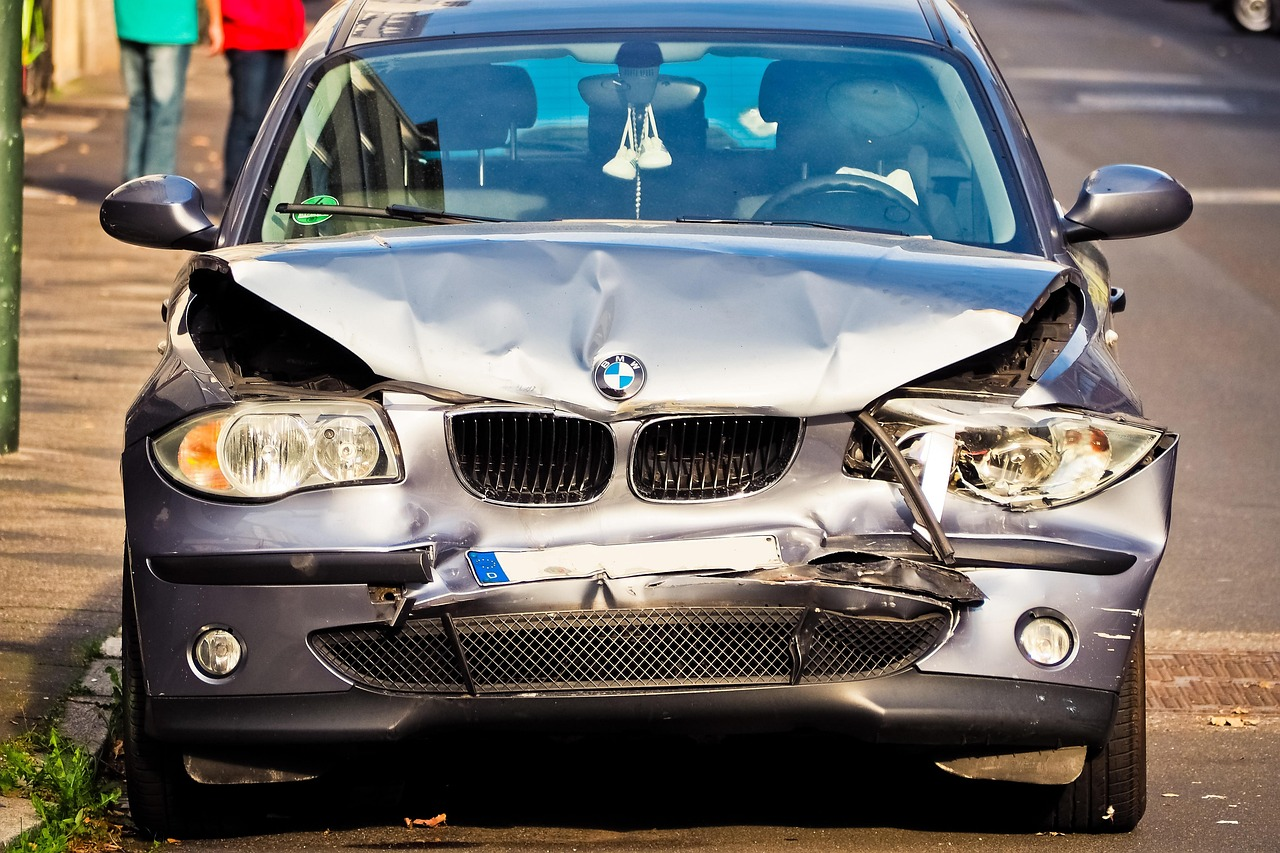

In [12]:
# ─── Test the Vision tool with a real damaged car photo ─────────────
#
# We'll download a sample damage photo from Google Drive.
# In a real app, the user would upload this from their phone after an accident.

import urllib.request                    # Standard library for HTTP downloads
import base64                            # For encoding image bytes as base64 strings
import os                                # For checking file existence

# Install gdown to download from Google Drive
!pip install gdown -q
import gdown

# Google Drive file ID of the sample photo, taken from its share link:
# https://drive.google.com/file/d/1Pz8leVNL-_QoeBBcOcw2fB7vmbj4k50B/view
DAMAGE_IMAGE_FILE_ID = "1Pz8leVNL-_QoeBBcOcw2fB7vmbj4k50B"
LOCAL_IMAGE_PATH = "/tmp/damage.jpg"

print("📥 Downloading sample damage photo from Google Drive...")

# Download the file using gdown
try:
    # id= works in every gdown version (gdown 6 removed the old fuzzy= option)
    gdown.download(id=DAMAGE_IMAGE_FILE_ID, output=LOCAL_IMAGE_PATH, quiet=True)
    if not os.path.exists(LOCAL_IMAGE_PATH) or os.path.getsize(LOCAL_IMAGE_PATH) == 0:
        raise Exception("File not downloaded or is empty.")
    print(f"✅ Image downloaded to {LOCAL_IMAGE_PATH}")
except Exception as e:
    print(f"❌ Error downloading image: {e}")
    print("Please ensure the Google Drive link is publicly accessible or shareable.")
    raise

# ─── Encode the image to base64 ─────────────────────────────────────
# OpenAI's Vision API expects images as base64-encoded strings, not as
# binary files or URLs.
with open(LOCAL_IMAGE_PATH, "rb") as f:
    # f.read() gives us bytes; b64encode converts to base64 bytes;
    # .decode("utf-8") converts to a regular string.
    image_b64 = base64.b64encode(f.read()).decode("utf-8")

print(f"✅ Image loaded ({len(image_b64):,} chars base64)")

# ─── Display the image inline so we can see what we're analyzing ────
from IPython.display import Image, display
display(Image(LOCAL_IMAGE_PATH, width=400))

In [13]:
# ─── Now invoke the Vision tool on our test image ───────────────────
#
# This is a real API call — takes a few seconds because the model
# needs to "see" and analyze the image.

print("🔍 Analyzing damage with the vision model (this takes a few seconds)...\n")

# Call our tool with the base64 image and an incident description.
# .invoke() expects a dict matching the tool's input schema.
result = analyze_damage_image_tool.invoke({
    "image_b64": image_b64,
    "incident_description": "Front collision with another vehicle",
})

# Pretty-print the JSON response so we can read it
# indent=2 makes the output nicely formatted with 2-space indentation
print(json.dumps(result, indent=2))


🔍 Analyzing damage with the vision model (this takes a few seconds)...



{
  "affected_parts": [
    {
      "part": "hood",
      "severity": "severe"
    },
    {
      "part": "front bumper",
      "severity": "severe"
    },
    {
      "part": "left headlight",
      "severity": "severe"
    },
    {
      "part": "right headlight",
      "severity": "severe"
    },
    {
      "part": "front grille",
      "severity": "moderate"
    },
    {
      "part": "front fenders",
      "severity": "moderate"
    }
  ],
  "overall_severity": "severe",
  "estimated_cost_inr": 120000,
  "description": "The front collision has heavily crumpled the hood and bumper, damaged both headlight areas, and displaced the grille and adjacent fender edges.",
  "repair_recommendation": "replace"
}


### 📝 Explanation

**What just happened?**

1. We downloaded a real photo of a damaged car
2. We encoded it as base64 (the format the OpenAI API expects)
3. We called `analyze_damage_image_tool` — which packaged the prompt + image and sent it to the model
4. The model **actually looked at the photo** and returned structured JSON about what it saw

**This is what makes our system "multimodal"** — it can process information from images, not just text. Notice how the output is:
- Listing specific car parts (front bumper, hood, etc.)
- Rating each one's severity (minor/moderate/severe)
- Providing a cost estimate in INR
- All in **structured JSON** that downstream tools can use

In a moment, our `estimate_payout` tool will take this output and calculate what the insurer should pay.

In [14]:
# ─── Tool 3: estimate_payout ─────────────────────────────────────────
#
# Now that we know the repair cost, we calculate what the insurer will
# actually pay. The formula depends on the plan type and applies
# depreciation + deductibles.

import secrets                  # For random claim reference numbers
from datetime import date       # For the year in the claim ID

# Payouts above this need a human surveyor visit before approval
SURVEYOR_THRESHOLD_INR = 50_000


def generate_claim_id() -> str:
    """Return a new claim reference like CLM-2026-48213 (demo: not stored anywhere)."""
    five_digit_number = 10_000 + secrets.randbelow(90_000)
    return f"CLM-{date.today().year}-{five_digit_number}"


class PayoutInput(BaseModel):
    estimated_repair_cost_inr: int = Field(description="Repair cost estimate from damage analysis")
    policy_idv: int = Field(description="Policy IDV (sum insured)")
    plan: str = Field(default="Comprehensive", description="Policy plan name")
    # Compulsory deductible — IRDAI sets this around ₹1,000–₹2,500
    deductible_inr: int = Field(default=2500, description="Compulsory deductible (default ₹2,500)")


@tool("estimate_payout", args_schema=PayoutInput)
def estimate_payout_tool(
    estimated_repair_cost_inr: int,
    policy_idv: int,
    plan: str = "Comprehensive",
    deductible_inr: int = 2500,
) -> dict:
    """Calculate the estimated insurance payout for a claim.

    Considers the policy plan, IDV cap, depreciation (unless Zero-Dep),
    and compulsory deductible.
    """
    # ─── Apply depreciation based on plan type ──────────────────────
    # Zero-Dep policies DON'T deduct depreciation — that's their whole point.
    # The check is case-insensitive ("Zero" or "zero" or "ZERO-DEP" all match).
    if "zero" in plan.lower() or "zero-dep" in plan.lower():
        depreciation_deduction = 0
        plan_note = "Zero Depreciation — no depreciation on parts"
    else:
        # Standard comprehensive: ~30% depreciation on parts on average.
        # In reality, this varies by material (plastic 50%, metal 0–30%).
        depreciation_deduction = int(estimated_repair_cost_inr * 0.30)
        plan_note = "Standard Comprehensive — 30% depreciation applied"

    # ─── Calculate payout: repair cost − depreciation − deductible ──
    payout_before_cap = estimated_repair_cost_inr - depreciation_deduction - deductible_inr

    # Two safety bounds:
    # 1. Payout can't go negative (max with 0)
    # 2. Payout can't exceed the IDV (the sum insured cap)
    payout = max(0, min(payout_before_cap, policy_idv))

    # ─── Total loss check ───────────────────────────────────────────
    # If repair cost > 75% of IDV, insurers usually declare total loss
    # and pay you the IDV instead of repairing. This threshold is industry standard.
    is_total_loss = estimated_repair_cost_inr > (policy_idv * 0.75)

    # Return the complete breakdown so the agent can explain it to the user
    return {
        "claim_id": generate_claim_id(),                              # Reference for the customer
        "surveyor_visit_required": payout > SURVEYOR_THRESHOLD_INR,  # Decided here, not by the LLM
        "estimated_repair_cost_inr": estimated_repair_cost_inr,
        "depreciation_deduction_inr": depreciation_deduction,
        "deductible_inr": deductible_inr,
        "estimated_payout_inr": payout,
        "is_total_loss": is_total_loss,
        "plan_note": plan_note,
        # Out-of-pocket = what the customer has to pay themselves
        "out_of_pocket_inr": estimated_repair_cost_inr - payout,
    }


# Bundle all 3 claims tools together
CLAIMS_TOOLS = [verify_policy_tool, analyze_damage_image_tool, estimate_payout_tool]
print(f"✅ Created {len(CLAIMS_TOOLS)} claims tools.")


# ─── Chain the Vision output into a payout calculation ──────────────
# If the Vision tool returned an estimated_cost_inr (it should have),
# we feed that into the payout tool — using a mock IDV of ₹8,50,000.
if "estimated_cost_inr" in result:
    payout = estimate_payout_tool.invoke({
        "estimated_repair_cost_inr": result["estimated_cost_inr"],
        "policy_idv": 850_000,
        "plan": "Comprehensive",
    })
    print("\n💰 Estimated payout for the photo above:")
    print(json.dumps(payout, indent=2))


✅ Created 3 claims tools.

💰 Estimated payout for the photo above:
{
  "claim_id": "CLM-2026-71332",
  "surveyor_visit_required": true,
  "estimated_repair_cost_inr": 120000,
  "depreciation_deduction_inr": 36000,
  "deductible_inr": 2500,
  "estimated_payout_inr": 81500,
  "is_total_loss": false,
  "plan_note": "Standard Comprehensive \u2014 30% depreciation applied",
  "out_of_pocket_inr": 38500
}


### 📝 Explanation

**The math behind a claim payout** (for non-Zero-Dep plans):

```
Payout = repair_cost − depreciation_deduction − deductible
       = repair_cost − (30% of repair_cost) − ₹2,500
```

So for a ₹50,000 repair:
- Depreciation: ₹15,000
- Deductible: ₹2,500
- **Payout: ₹32,500**
- **You pay out-of-pocket: ₹17,500**

This is why **Zero-Dep is worth it for newer cars** — you get the full repair amount minus just the deductible.

**Total loss check**: If the repair would cost more than 75% of the IDV, insurers usually declare the car a total loss and pay you the IDV instead of repairing. We flag this so the Claims Agent can tell the customer.

**You've just built a complete claims pipeline:**
- Verify the policy ✅
- Analyze the damage with AI Vision ✅
- Calculate what to pay ✅

In production, you'd add: garage referral, surveyor assignment, fraud detection, document collection. But the core decision-making loop is what we just built.

---
# 📖 Section 6 — RAG Tool (ChromaDB + Embeddings)

The third tool category is **Retrieval-Augmented Generation (RAG)** — letting the LLM search a knowledge base of policy documents before answering questions.

## 🤔 Why RAG?

LLMs are great at **understanding language** but bad at **knowing specific facts** (especially regulatory documents that change yearly). RAG solves this by:

1. Storing your documents in a vector database
2. When the user asks a question, finding the most relevant chunks
3. Giving those chunks to the LLM as context

This way the LLM answers from your **actual policy docs**, not its training data.

In [15]:
# ─── Section 6 — RAG: build the knowledge base ──────────────────────
#
# We need documents to retrieve from. In production, you'd ingest hundreds
# of PDFs (policy wordings, IRDAI circulars, FAQs). For this lab, we
# create 3 short markdown docs in a dict.

# Each key is the "source filename" — used so the agent can cite the source
# of its answer (e.g., "Per IRDAI guidelines..." vs "Per FAQ...").
KNOWLEDGE_BASE = {
    "irdai_guidelines.md": """# IRDAI Motor Insurance Guidelines

## Mandatory Coverage
Third-party liability cover is mandatory under the Motor Vehicles Act, 1988.
Driving without valid third-party insurance is a punishable offence with a fine
up to ₹2,000 and/or imprisonment up to 3 months for first offence.

## IDV Calculation
IDV is the maximum amount insurer will pay if your car is stolen or totaled.
Depreciation slabs per IRDAI:
- 0–6 months: 5%
- 6 months–1 year: 15%
- 1–2 years: 20%
- 2–3 years: 30%
- 3–4 years: 40%
- 4–5 years: 50%
- 5+ years: mutually agreed

## NCB Ladder
- After 1 claim-free year: 20%
- After 2 years: 25%
- After 3 years: 35%
- After 4 years: 45%
- After 5+ years: 50%

NCB belongs to the policyholder, not the vehicle. Transferable via NCB
retention letter, valid for 3 years.

## Claim Settlement Timeline
- Acknowledge within 7 days
- Surveyor appointed within 24–72 hours for claims > ₹50,000
- Final settlement within 30 days of complete documentation
""",

    "policy_terms.md": """# Motor Policy Terms

## What is Covered (Comprehensive Plan)
- Accident, collision, impact
- Fire, explosion, lightning
- Theft, burglary
- Riots, strikes, terrorism
- Earthquake, flood, cyclone, storm, hailstorm
- Third-party legal liability
- Personal Accident cover for owner-driver: ₹15 lakh

## What is NOT Covered
- Normal wear and tear, mechanical breakdown
- Driving without valid license
- Driving under influence of alcohol/drugs
- Outside India's geographical area
- War, nuclear risk
- Consequential losses (loss of earnings, hotel stay)

## Add-on Covers
- Zero Depreciation: no depreciation on parts at claim
- Engine Protection: covers hydrostatic lock, water ingression
- Roadside Assistance: 24x7 towing, fuel, lockout help
- Return to Invoice: pays original invoice price on total loss
""",

    "faqs.md": """# Frequently Asked Questions

## Q: Can I transfer my NCB to a new car?
Yes. NCB is tied to you, not the car. Get an NCB Retention Letter from your
current insurer — valid 3 years.

## Q: My policy expired 2 months ago. Can I renew?
Yes, you can renew up to 90 days post-expiry without losing accumulated NCB.
Beyond 90 days, NCB is lost.

## Q: What is Zero Depreciation?
An add-on where insurer doesn't deduct depreciation on replaced parts.
Best for cars under 5 years old. Adds ~15% to OD premium.

## Q: Will a small claim affect my NCB?
Yes — any claim resets NCB to 0. If claim amount is small and NCB discount
is significant, often cheaper to pay out of pocket.

## Q: What is a deductible?
The amount you pay before insurance kicks in. Compulsory deductible is set
by IRDAI (~₹1,000–₹2,500). Voluntary deductible gives premium discount.
""",
}

# Quick stats so the user knows what got loaded
print(f"📚 Knowledge base contains {len(KNOWLEDGE_BASE)} documents:")
for name in KNOWLEDGE_BASE:
    print(f"   • {name} ({len(KNOWLEDGE_BASE[name]):,} chars)")


📚 Knowledge base contains 3 documents:
   • irdai_guidelines.md (964 chars)
   • policy_terms.md (805 chars)
   • faqs.md (846 chars)


In [16]:
# ─── Embed the documents and store them in ChromaDB ──────────────────
#
# This is the heart of RAG. We:
# 1. Split each document into chunks (small enough to fit in context)
# 2. Run each chunk through an embedding model → get a vector
# 3. Store (chunk text, vector, metadata) in ChromaDB
# 4. Later, we'll query by similarity to find relevant chunks

import chromadb                                # Vector database
from chromadb.config import Settings           # ChromaDB config options
from langchain_openai import OpenAIEmbeddings  # OpenAI's embedding model

# ─── Create an in-memory ChromaDB client ─────────────────────────────
# In production you'd use chromadb.PersistentClient(path="/some/dir") to
# persist data across restarts. For Colab, in-memory is fine.
chroma_client = chromadb.Client(Settings(anonymized_telemetry=False))

# A "collection" in ChromaDB is like a table in a SQL database.
# get_or_create_collection() means: create if it doesn't exist, else reuse.
collection = chroma_client.get_or_create_collection(name="insurance_kb")

# ─── Initialize the OpenAI embeddings model ──────────────────────────
# text-embedding-3-small turns text into 1,536-dimensional vectors.
# It's OpenAI's cheapest embedding model and works great for general use.
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

# ─── Chunk the documents ─────────────────────────────────────────────
# We need 4 parallel lists: chunks, metadata, IDs, and (later) vectors.
chunks = []           # The actual text content
metadatas = []        # Source filename per chunk
ids = []              # Unique ID per chunk (ChromaDB requires this)
chunk_id = 0          # Counter for generating unique IDs

# Loop through each document in our knowledge base
for source, text in KNOWLEDGE_BASE.items():
    # Simple chunking strategy: split on "## " (markdown subheadings)
    # Each section becomes one chunk. This works because each section is
    # roughly one topic.
    sections = [s.strip() for s in text.split("\n## ") if s.strip()]

    for section in sections:
        # Skip sections that are too short to be useful (less than 50 chars)
        # — these are usually just headers with no content
        if len(section) < 50:
            continue

        chunks.append(section)
        metadatas.append({"source": source})    # Remember where it came from
        ids.append(f"chunk_{chunk_id}")
        chunk_id += 1

print(f"📦 Created {len(chunks)} chunks from {len(KNOWLEDGE_BASE)} documents")

# ─── Generate embeddings for all chunks AT ONCE ──────────────────────
# Batching is much cheaper than embedding one chunk at a time —
# OpenAI charges per token, but the per-call overhead is fixed.
print("🧠 Generating embeddings...")
vectors = embeddings.embed_documents(chunks)
# Each vector is a list of 1,536 floats representing the meaning of one chunk.

# ─── Add everything to ChromaDB in one batch ─────────────────────────
# Parameters: text, embeddings, metadata, and unique IDs (all parallel lists)
collection.add(
    documents=chunks,
    embeddings=vectors,
    metadatas=metadatas,
    ids=ids,
)

print(f"✅ Indexed {collection.count()} chunks into ChromaDB")


📦 Created 12 chunks from 3 documents
🧠 Generating embeddings...


✅ Indexed 12 chunks into ChromaDB


### 📝 Explanation

**What is an embedding?**

An embedding is a numerical representation of text as a list of numbers (a "vector"). Text with similar meaning produces similar vectors. So if we embed "What is NCB?" and "No Claim Bonus explained", the vectors will be close to each other in space — even though they share zero words.

**The flow:**
1. Take each chunk of text
2. Run it through OpenAI's `text-embedding-3-small` → get a 1,536-dimensional vector
3. Store the vector + the original text in ChromaDB
4. Later, when a user asks a question, embed the question too, then find chunks whose vectors are nearest

**Chunking strategy**: We split on `## ` Markdown headers. This works well because each section is roughly one topic. In production, you'd use smarter chunkers (e.g. `RecursiveCharacterTextSplitter` from LangChain) that handle long sections, overlap, and structure preservation.

**Cost**: Embedding 18 chunks costs about **$0.0001** — fractions of a cent.

In [17]:
# ─── The RAG tool: search the knowledge base ────────────────────────
#
# This tool takes a question, embeds it, finds the most similar chunks
# in ChromaDB, and returns them. The agent then uses those chunks as
# context to ground its answer.

class KBSearchInput(BaseModel):
    query: str = Field(description="Question or topic to search the policy knowledge base for")
    # top_k = how many chunks to return. 3 is usually enough.
    top_k: int = Field(default=3, description="Number of relevant chunks to retrieve")


@tool("policy_kb_search", args_schema=KBSearchInput)
def policy_kb_search_tool(query: str, top_k: int = 3) -> dict:
    """Search the insurance policy and IRDAI regulations knowledge base.

    Use this for any policy-related question: coverage, exclusions, NCB rules,
    claim process, IRDAI guidelines, etc.
    """
    # ─── Step 1: Embed the user's query ─────────────────────────────
    # Same model that embedded the documents — important for similarity to work!
    # If you embedded docs with one model and queries with another, similarity
    # results would be garbage.
    query_vec = embeddings.embed_query(query)

    # ─── Step 2: Search ChromaDB for nearest neighbors ──────────────
    # query_embeddings expects a LIST of query vectors (we have one).
    # n_results = how many chunks to return per query.
    results = collection.query(
        query_embeddings=[query_vec],
        n_results=top_k,
    )

    # ─── Step 3: Format the results ─────────────────────────────────
    # ChromaDB returns results in parallel lists. We unpack them into
    # a list of dicts for easy use by the agent.
    chunks_found = []
    # results["documents"][0] = the text of the matching chunks
    # results["metadatas"][0] = their metadata (source filename, etc.)
    # zip() pairs them up
    for doc, meta in zip(results["documents"][0], results["metadatas"][0]):
        chunks_found.append({
            "content": doc,
            "source": meta.get("source", "unknown"),
        })

    return {"query": query, "results": chunks_found}


# Bundle RAG tools together (just one for now)
RAG_TOOLS = [policy_kb_search_tool]


# ─── Test it! ────────────────────────────────────────────────────────
# Watch how the search returns content about NCB even though our query
# uses different words than the source documents.
print("🔍 Testing the RAG tool...\n")
result = policy_kb_search_tool.invoke({"query": "What is NCB and how is it transferred?"})

# Print the top results
for i, chunk in enumerate(result["results"], 1):
    print(f"--- Result {i} (from {chunk['source']}) ---")
    print(chunk["content"][:300])  # First 300 chars per chunk
    print()


🔍 Testing the RAG tool...



--- Result 1 (from faqs.md) ---
Q: Can I transfer my NCB to a new car?
Yes. NCB is tied to you, not the car. Get an NCB Retention Letter from your
current insurer — valid 3 years.

--- Result 2 (from irdai_guidelines.md) ---
NCB Ladder
- After 1 claim-free year: 20%
- After 2 years: 25%
- After 3 years: 35%
- After 4 years: 45%
- After 5+ years: 50%

NCB belongs to the policyholder, not the vehicle. Transferable via NCB
retention letter, valid for 3 years.

--- Result 3 (from faqs.md) ---
Q: Will a small claim affect my NCB?
Yes — any claim resets NCB to 0. If claim amount is small and NCB discount
is significant, often cheaper to pay out of pocket.



### 📝 Explanation

**Watch how this works:**

1. User asks: *"What is NCB and how is it transferred?"*
2. We embed that question → vector
3. ChromaDB finds the 3 chunks with vectors **closest** to it
4. We return those chunks to the LLM as context
5. The LLM uses them to answer

**Notice the magic**: The user said "NCB" but our knowledge base says "No Claim Bonus" in some places. Embeddings handle that — they understand **meaning**, not just keywords.

**You've now built all 7 tools.** Time to give them to agents.

---
# 🗂️ Section 7 — LangGraph State

In LangGraph, every conversation has a **state** — a dictionary that flows through every node in the graph. Each node reads from it and returns updates to it.

Think of it as a **shared whiteboard** that all agents can read and write to.

In [18]:
# ─── Section 7 — Define the LangGraph state ─────────────────────────
#
# State is the shared "whiteboard" that flows through every node in the graph.
# Each node reads from it and returns updates that get merged back in.

from typing import Annotated, Literal, TypedDict, Optional
from langgraph.graph.message import add_messages

# We use TypedDict (not Pydantic) because LangGraph optimizes for it.
# TypedDict tells type-checkers what keys exist, but at runtime it's
# just a regular dict.


class AgentState(TypedDict):
    """The state that flows through our LangGraph workflow.

    Every node receives this state, can read from it, and returns
    updates that get merged back into it.
    """

    # ─── Conversation history ──────────────────────────────────────
    # Annotated[list, add_messages] is the special LangGraph pattern.
    # The `add_messages` reducer tells LangGraph: "when a node returns
    # new messages, APPEND them to the existing list, don't replace."
    # Without this, every node would wipe out the conversation history!
    messages: Annotated[list, add_messages]

    # ─── Routing: which agent handles the current turn? ─────────────
    # Literal[...] restricts the value to one of the listed strings.
    # Optional[X] means "X or None".
    intent: Optional[Literal["quote", "claim", "policy_qa"]]
    next_agent: Optional[str]

    # ─── Domain context — populated by agents over the conversation ─
    # These dicts let agents share information. E.g., if Quote Agent
    # saved the vehicle info, Claims Agent could read it later.
    vehicle: Optional[dict]
    customer: Optional[dict]
    quote_result: Optional[dict]
    claim_result: Optional[dict]

    # ─── Damage photo for claim flow ────────────────────────────────
    # Stored as a base64 string until the claims agent has analysed it.
    damage_image_b64: Optional[str]

    # True only for the message that carried a NEW photo (reset every turn).
    # The supervisor uses this flag — not the stored photo — to send that
    # message straight to claims.
    image_uploaded_this_turn: Optional[bool]


print("✅ AgentState defined!")
print("\nFields in the state:")
for field in AgentState.__annotations__:
    print(f"   • {field}")


✅ AgentState defined!

Fields in the state:
   • messages
   • intent
   • next_agent
   • vehicle
   • customer
   • quote_result
   • claim_result
   • damage_image_b64
   • image_uploaded_this_turn


### 📝 Explanation

**What's the `Annotated[list, add_messages]` thing?**

`messages` is a special field because we want to **append** to it, not **overwrite** it. The `add_messages` reducer tells LangGraph: "when a node returns new messages, append them to the existing list instead of replacing it."

Without this, every node's response would wipe out the conversation history. With it, the history grows naturally.

**Why TypedDict instead of Pydantic?**

LangGraph specifically supports TypedDict for state. It's lighter-weight than Pydantic and plays well with LangGraph's update merging. (You can also use Pydantic; both work.)

**The state acts as memory.** When the user says "buy that comprehensive plan", the Quote Agent can look at `state["quote_result"]` to know which quote they're referring to. State is how agents stay in context across turns.

---
# 🎯 Section 8 — The Supervisor (Intent Router)

The supervisor is the **traffic cop** of our multi-agent system. Its only job is to look at the user's latest message and decide which specialist agent should respond.

## 🧠 Why have a supervisor?

You could put all 7 tools on one big agent. But that creates problems:
- The LLM has to consider too many options → slower + more errors
- Easier to hallucinate ("call analyze_damage_image with random base64")
- Harder to debug ("which tool did it actually use?")

A supervisor pattern **scopes** each agent to a clear domain, making them faster, cheaper, and more accurate.

In [19]:
# ─── Section 8 — The Supervisor (intent router) ─────────────────────
#
# The supervisor is the traffic cop. Its only job: look at the user's
# message and route to the right specialist agent.
#
# Why a separate supervisor? Because trying to put all 7 tools on one
# big agent makes it slow, expensive, and prone to errors. Specialists
# are faster, cheaper, and more accurate.

from langchain_core.messages import SystemMessage, HumanMessage, AIMessage

# ─── The supervisor's system prompt ─────────────────────────────────
# This is what defines its job. Notice:
# - Clear description of each agent's scope
# - Examples for each category (helps the LLM classify accurately)
# - Strict output format (just JSON, no extra text)

SUPERVISOR_PROMPT = """You are the supervisor of a car insurance AI system. Your only job is to classify
the user's intent and decide which specialist agent should handle their request.

You have 3 specialist agents:

1. **quote** — handles requests for premium quotes, vehicle insurance pricing.
   Examples: "I want a quote for my Maruti Swift", "How much will insurance cost?"

2. **claims** — handles claim filing, damage assessment, policy verification.
   Examples: "I had an accident", "I want to file a claim", "Help me with damage"

3. **policy_qa** — answers questions about policy terms, coverage, IRDAI rules.
   Examples: "What is NCB?", "Is flood damage covered?", "What does IDV mean?"

Respond ONLY with valid JSON (no markdown, no extra text):
{"intent": "quote" | "claim" | "policy_qa", "reasoning": "<one short sentence>"}

If unclear, default to "policy_qa".
"""

# The prompt names the agents "quote / claims / policy_qa" but asks for the
# intents "quote / claim / policy_qa" — and the model sometimes answers with
# the agent's name. We accept both spellings.
INTENT_ALIASES = {
    "claims": "claim",
    "claim": "claim",
    "quotes": "quote",
    "quote": "quote",
    "policy": "policy_qa",
    "policy_qa": "policy_qa",
}

# Extra rules so the supervisor understands follow-up messages
CONTINUATION_RULES = """
CONTEXT RULES:
- You may be told which flow is already in progress and the assistant's last message.
- If the new message answers or continues that flow (a date, a place, a pincode, a policy
  number, a car model, yes/no, "the first plan"), keep the same intent.
  Example: during a claim, "It happened yesterday near Lonavala" is claim.
- If the new message asks something different, choose the intent that fits the new message,
  even if a claim or quote is in progress. Example: during a claim, "What is NCB?" is policy_qa.
"""


def build_classifier_input(state: AgentState, latest_user_message: str) -> str:
    """Build the text the classifier sees: the flow in progress, the agent's last reply, the new message."""
    current_intent = state.get("intent")
    if current_intent not in ("quote", "claim", "policy_qa"):
        return latest_user_message      # First message of the conversation

    # Keep the END of the last reply: agents put their follow-up question last
    last_assistant_reply = ""
    for past_message in reversed(state["messages"]):
        if isinstance(past_message, AIMessage) and past_message.text:
            last_assistant_reply = past_message.text[-800:]
            break

    return (
        f"Flow in progress: {current_intent}\n"
        f"Assistant's last message: {last_assistant_reply or '(none)'}\n"
        f"New user message: {latest_user_message}"
    )


def supervisor_node(state: AgentState) -> dict:
    """The supervisor node — classifies intent and routes to the right agent."""

    # ─── Get the chat model ─────────────────────────────────────────
    # reasoning_effort="none" (set in get_chat_model) keeps routing fast
    # and cheap — classification doesn't need the model to think.
    llm = get_chat_model()

    # ─── Find the latest human message ──────────────────────────────
    # state["messages"] is the full conversation history. We filter to
    # just the human messages and take the most recent one.
    user_messages = [m for m in state["messages"] if getattr(m, "type", None) == "human"]
    if not user_messages:
        # No user messages yet — default to policy_qa (safest fallback)
        return {"intent": "policy_qa", "next_agent": "policy_qa"}

    latest_user_msg = user_messages[-1].content

    # ─── Shortcut: a photo sent WITH THIS MESSAGE is a claim ────────
    # We don't even need to call the LLM for this case. Saves money
    # and is more reliable than LLM classification. We check the
    # per-message flag, not the stored photo — otherwise every later
    # message (even "What is NCB?") would be forced into claims.
    if state.get("image_uploaded_this_turn"):
        return {"intent": "claim", "next_agent": "claims"}

    # ─── Otherwise, ask the LLM to classify ─────────────────────────
    # We also tell it which flow is in progress and what the agent last
    # asked, so a short answer like "yesterday, near Lonavala" stays in
    # the claim instead of being read as a brand-new question.
    classifier_input = build_classifier_input(state, latest_user_msg)
    response = llm.invoke([
        SystemMessage(content=SUPERVISOR_PROMPT + CONTINUATION_RULES),
        {"role": "user", "content": classifier_input},
    ])

    # ─── Parse the JSON response ────────────────────────────────────
    # Strip code fences if the LLM accidentally added them
    content = response.text.strip()
    if content.startswith("```"):
        content = content.split("```")[1]
        if content.startswith("json"):
            content = content[4:]
        content = content.strip()

    try:
        decision = json.loads(content)
        intent = decision.get("intent", "policy_qa")
    except json.JSONDecodeError:
        # If parsing fails, default to policy_qa (safest)
        intent = "policy_qa"

    # Accept "claims" as well as "claim" (see INTENT_ALIASES above).
    # Anything unrecognised falls back to policy_qa (safest).
    intent = INTENT_ALIASES.get(str(intent).strip().lower(), "policy_qa")

    # Map the intent name → agent node name
    intent_to_agent = {"quote": "quote", "claim": "claims", "policy_qa": "policy_qa"}
    next_agent = intent_to_agent.get(intent, "policy_qa")

    # Return the updates to merge back into state
    return {"intent": intent, "next_agent": next_agent}


def route_from_supervisor(state: AgentState) -> str:
    """Conditional edge function — tells LangGraph which node to go to next.

    LangGraph calls this AFTER supervisor_node runs. The return value
    must be a node name (a string).
    """
    return state.get("next_agent") or "policy_qa"


# ─── Test the supervisor with sample messages ───────────────────────
from langchain_core.messages import HumanMessage

test_messages = [
    "I want a quote for my Maruti Swift",        # Should route to quote
    "I had an accident yesterday",                # Should route to claims
    "What is NCB?",                                # Should route to policy_qa
    "Can I transfer my insurance to a new car?", # Should route to policy_qa
]

print("Testing supervisor routing:\n")
for msg in test_messages:
    # Build a minimal state with just one user message
    test_state = {"messages": [HumanMessage(content=msg)]}
    result = supervisor_node(test_state)
    print(f"  \"{msg}\"")
    print(f"     → intent: {result['intent']}, route to: {result['next_agent']}\n")


Testing supervisor routing:



  "I want a quote for my Maruti Swift"
     → intent: quote, route to: quote



  "I had an accident yesterday"
     → intent: claim, route to: claims



  "What is NCB?"
     → intent: policy_qa, route to: policy_qa



  "Can I transfer my insurance to a new car?"
     → intent: policy_qa, route to: policy_qa



### 📝 Explanation

**The supervisor in 4 ideas:**

1. **It runs with reasoning switched off** (`reasoning_effort="none"`) because classification is easy — that keeps routing fast and cheap
2. **It returns structured JSON**, which we parse to extract the intent. The model sometimes answers with the agent's name (`"claims"`) instead of the intent (`"claim"`), so we accept both spellings — without that, claims were silently sent to Policy Q&A
3. **It has a deterministic shortcut**: if a photo arrived *with this message*, it MUST be a claims case — we don't even ask the LLM. We check a per-message flag, not the stored photo; otherwise every later message would be forced into claims
4. **It knows the conversation**: we tell it which flow is in progress and what the agent last asked, so "yesterday, near Lonavala" stays in the claim while "What is NCB?" switches to Q&A

**The `route_from_supervisor` function** is what LangGraph calls a "conditional edge". After the supervisor node runs, LangGraph calls this function to figure out which node to go to next. We just return the name of the next node.

**Cost tip**: the supervisor runs on *every* message, so keep it cheap. With a reasoning model, the biggest lever is `reasoning_effort` — classification doesn't need the model to think.

---
# 🤖 Section 9 — The Three Specialist Agents

Each specialist is just an LLM with:
- A **system prompt** describing its role
- A **specific set of tools** it can call

That's it. The LangGraph framework handles the routing and tool execution.

In [20]:
# ─── Section 9 — Define the 3 specialist agents ─────────────────────
#
# Each agent is just an LLM with:
#  1. A system prompt describing its role
#  2. A specific list of tools it can call
#
# LangGraph handles the routing and tool execution — we just need to
# define these "node functions" that take state and return updates.


# ─── Agent 1: Quote Agent ────────────────────────────────────────────
# Handles premium calculations. It chains several tool calls
# (lookup → calculate) in the right order on its own.

QUOTE_AGENT_PROMPT = """You are a friendly Indian motor insurance quote specialist for AutoShield.

Your job: help the customer get an instant car insurance premium quote.

You need:
1. Vehicle make + model (e.g., Maruti Swift, Hyundai Creta)
2. Vehicle age in years
3. NCB (claim-free years, 0 if first-time)
4. Pincode (optional, for risk loading)

WORKFLOW:
- Ask for vehicle name → use `vehicle_lookup` tool to get specs
- Once you have age + NCB → use `calculate_premium` for all 3 plans
- If user gives pincode → use `pincode_risk` to check the area
- Present all 3 plans with INR prices using Indian numbering (₹1,23,456)

Be concise. Ask one question at a time. Currency: INR (₹). Today is 2026.
"""


def quote_agent_node(state: AgentState) -> dict:
    """Quote agent — bound to QUOTE_TOOLS only."""

    # .bind_tools() tells the LLM: "These are the only tools you can call."
    # The LLM sees the tool schemas in its context and decides whether to call
    # any of them when responding.
    llm = get_chat_model().bind_tools(QUOTE_TOOLS)

    # Prepend the system prompt to the conversation history.
    # The system message defines the agent's role and is read first.
    messages = [SystemMessage(content=QUOTE_AGENT_PROMPT)] + state["messages"]

    # Call the LLM. It returns an AIMessage that might contain tool calls.
    response = llm.invoke(messages)

    # Return the new message to be merged into state["messages"]
    return {"messages": [response]}


# ─── Agent 2: Claims Agent ───────────────────────────────────────────
# Handles FNOL (First Notice of Loss), including the photo analysis.

CLAIMS_AGENT_PROMPT = """You are a Claims Specialist for AutoShield Motor Insurance.

You handle FNOL (First Notice of Loss) — taking customers through claims quickly and empathetically.

INFORMATION YOU NEED:
1. Policy number (format: POL-YYYY-NNNNN)
2. What happened — a short description
3. A damage photo (uploadable through UI)
Date and place are useful but OPTIONAL — never hold up the assessment for them.

WORKFLOW — use only what is still missing; never ask for something the customer already said:
- Start with empathy ("Sorry to hear about the incident")
- Policy number given → call `verify_policy`. If not, ask for it.
- Photo available (see the system note) and a description → call `analyze_damage_image`
- ONLY AFTER you have the `analyze_damage_image` result → call `estimate_payout` with
  estimated_repair_cost_inr = its `estimated_cost_inr` and policy_idv = the `idv` from
  `verify_policy`. Never guess a repair cost.
- Tools run one at a time: call one, read its result, then decide the next call.
- Policy number + description + photo in one message → do all of the above now and
  present the summary; don't stop to ask questions first.
- Claim summary, with the numbers exactly as the tools returned them: claim ID, damage,
  repair cost, payout, out-of-pocket, next steps (garage referral; a surveyor visit
  ONLY if `surveyor_visit_required` is true)
- If date or place are missing, ask for them at the END, for the claim record.

Every rupee figure must come from a tool result — never compute your own.
Format INR with Indian commas (₹1,23,456). Don't dump tool JSON — present results conversationally.
"""


def claims_agent_node(state: AgentState) -> dict:
    """Claims agent — bound to CLAIMS_TOOLS (including the Vision tool)."""

    # parallel_tool_calls=False: one tool per step, so estimate_payout can only
    # run AFTER the photo analysis comes back. (When the tools ran in parallel,
    # the model had to guess the repair cost before it had seen the estimate.)
    llm = get_chat_model().bind_tools(CLAIMS_TOOLS, parallel_tool_calls=False)

    # ─── If a damage image is in state, tell the agent ──────────────
    # The agent itself doesn't see the raw image bytes — only state holds them.
    # We append a note so the agent knows to call analyze_damage_image,
    # and our tool executor will inject the actual bytes at runtime.
    extra_context = ""
    if state.get("damage_image_b64"):
        extra_context = (
            "\n\n[SYSTEM NOTE: The customer has uploaded a damage photo with their "
            "message, and it is available. When you call `analyze_damage_image`, "
            "pass image_b64='__USE_STATE_IMAGE__' — the system substitutes the "
            "actual image bytes at runtime.]"
        )

    messages = [SystemMessage(content=CLAIMS_AGENT_PROMPT + extra_context)] + state["messages"]
    response = llm.invoke(messages)

    return {"messages": [response]}


# ─── Agent 3: Policy Q&A Agent ───────────────────────────────────────
# Answers policy questions using RAG. The heavy lifting is done by
# retrieval; the LLM just synthesizes.

POLICY_QA_PROMPT = """You are a knowledgeable Indian motor insurance advisor.

Answer customer questions about insurance policies, coverage, claims process,
IRDAI regulations, NCB, IDV, add-ons, exclusions.

WORKFLOW:
- For ANY policy question → ALWAYS call `policy_kb_search` first
- Use retrieved context to ground your answer — don't make things up
- If KB doesn't have the answer, say so honestly

STYLE:
- Concise, plain-language. Indian English. ₹ and Indian numbering.
- 2–4 sentences for simple questions.
- When the documents give a ladder, table or list of figures (e.g. the NCB ladder),
  show every figure as a short bullet list — don't compress it to "20% to 50%"
- If user shifts to wanting a quote/claim, just answer current question.
  The supervisor will route them next turn.

Today is 2026.
"""


def policy_qa_agent_node(state: AgentState) -> dict:
    """Policy Q&A agent — bound to RAG_TOOLS only."""

    # On the first step of a turn (the last message is the user's question),
    # REQUIRE a knowledge-base search with tool_choice. The prompt alone is not
    # enough: after a long claim or quote conversation the model sometimes
    # answered from general knowledge. Once the results are back, the model
    # is free to write the answer.
    is_first_step_of_turn = isinstance(state["messages"][-1], HumanMessage)
    if is_first_step_of_turn:
        llm = get_chat_model().bind_tools(RAG_TOOLS, tool_choice="policy_kb_search")
    else:
        llm = get_chat_model().bind_tools(RAG_TOOLS)

    messages = [SystemMessage(content=POLICY_QA_PROMPT)] + state["messages"]
    response = llm.invoke(messages)

    return {"messages": [response]}


print("✅ All 3 specialist agents defined!")


✅ All 3 specialist agents defined!


### 📝 Explanation

**Three agents, three patterns. Notice the differences:**

| Agent | Tools | How it calls them |
|---|---|---|
| Quote | 3 (lookup, premium, pincode) | Chains tool calls in order on its own |
| Claims | 3 (verify, vision, payout) | **One tool at a time** (`parallel_tool_calls=False`) so the payout uses the photo's estimate |
| Policy Q&A | 1 (RAG) | **Must search first** (`tool_choice="policy_kb_search"`) so answers come from our documents |

All three use the same model (`gpt-6-luna` via `get_chat_model()`). Each agent's specialty comes from its **prompt and tools**, not from a different model.

**What's `.bind_tools(QUOTE_TOOLS)` doing?**

It tells the LLM: "These are the only tools you can call." The LLM gets the tool schemas in its context window and decides whether to call any of them when responding.

**The system prompts are the secret sauce.** Each one:
- Defines the agent's role clearly
- Specifies the workflow (what to do in what order)
- Sets style guidelines (Indian numbering, INR, conversational tone)
- Tells the agent how to handle edge cases

Rule of thumb: **80% of agent behavior is in the system prompt.** Iterate on the prompt before iterating on the code.

---
# 🕸️ Section 10 — Wire It All Together with LangGraph

Now we have all the pieces. Time to wire them into a **graph** where messages flow between nodes.

## 📊 The graph we'll build

```
START
  │
  ▼
[supervisor] → routes to one of:
  │
  ├──▶ [quote_agent] ──▶ [tool_executor] ──▶ (loops back to quote)
  ├──▶ [claims_agent] ─▶ [tool_executor] ──▶ (loops back to claims)
  └──▶ [policy_qa_agent] ▶ [tool_executor] ─▶ (loops back to policy_qa)
                                              │
                                              ▼
                                            END
```

The **loop-back** is important: after a tool runs, the agent needs to see the result and decide its next move (either call more tools or finalize its response).

In [21]:
# ─── Section 10 — Tool executor node ────────────────────────────────
#
# When an agent decides to call a tool, that tool needs to actually run.
# LangGraph has a built-in tool node, but we write a custom one because
# we need special handling for the vision tool (which needs the image
# from state, not from the LLM's tool-call args).

from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import ToolMessage, AIMessage


# ─── Bundle ALL tools into one registry ─────────────────────────────
# The tool executor needs to know how to call every tool. We combine
# all 3 categories into a single dict for fast lookup by name.
ALL_TOOLS = QUOTE_TOOLS + CLAIMS_TOOLS + RAG_TOOLS
TOOL_REGISTRY = {t.name: t for t in ALL_TOOLS}


def tool_executor_node(state: AgentState) -> dict:
    """Execute the tool calls from the most recent AI message.

    This runs AFTER an agent has decided to call one or more tools.
    """
    # Look at the LAST message in state — it should be the agent's response
    last_msg = state["messages"][-1]

    # ─── Guard: only proceed if last message has tool calls ─────────
    # If the agent didn't call any tools (gave a final response instead),
    # there's nothing to do — return an empty update.
    if not isinstance(last_msg, AIMessage) or not last_msg.tool_calls:
        return {}

    # ─── Run each tool call and collect results ─────────────────────
    tool_messages = []                          # Results we'll send back to the agent
    image_was_analysed = False                  # Set once the photo has been assessed

    # An agent can call MULTIPLE tools in a single turn (e.g., lookup + calculate)
    for tool_call in last_msg.tool_calls:
        name = tool_call["name"]                # Tool name (e.g., "vehicle_lookup")
        args = dict(tool_call["args"])          # Tool arguments (LLM-generated)

        # ─── Special case: inject image from state for vision tool ──
        # The agent passed image_b64="__USE_STATE_IMAGE__" as a placeholder.
        # We substitute the real bytes here so the agent never has to handle
        # the raw image bytes (which would bloat its context window).
        if name == "analyze_damage_image":
            if state.get("damage_image_b64"):
                args["image_b64"] = state["damage_image_b64"]
            else:
                # No image in state — return an error to the agent
                tool_messages.append(ToolMessage(
                    content=json.dumps({"error": "No damage image in state"}),
                    tool_call_id=tool_call["id"],
                    name=name,
                ))
                continue

        # ─── Validate the tool exists ───────────────────────────────
        if name not in TOOL_REGISTRY:
            tool_messages.append(ToolMessage(
                content=json.dumps({"error": f"Unknown tool: {name}"}),
                tool_call_id=tool_call["id"],
                name=name,
            ))
            continue

        # ─── Actually call the tool ─────────────────────────────────
        try:
            # .invoke() runs the tool with the given args
            result = TOOL_REGISTRY[name].invoke(args)

            # Wrap the result in a ToolMessage. The tool_call_id links this
            # result back to the specific tool call the agent made.
            tool_messages.append(ToolMessage(
                content=json.dumps(result, default=str),  # JSON-serialize the result
                tool_call_id=tool_call["id"],
                name=name,
            ))
            if name == "analyze_damage_image" and "error" not in result:
                image_was_analysed = True
        except Exception as e:
            # Tool execution failed — tell the agent what went wrong
            tool_messages.append(ToolMessage(
                content=json.dumps({"error": f"{type(e).__name__}: {e}"}),
                tool_call_id=tool_call["id"],
                name=name,
            ))

    # Return all the tool results to be appended to state["messages"].
    # The agent will see these results and decide what to do next.
    state_update = {"messages": tool_messages}
    # Drop the photo once it has been analysed: the result is now in the
    # conversation, and the claims agent shouldn't analyse it again next turn.
    if image_was_analysed:
        state_update["damage_image_b64"] = None
    return state_update


# ─── Conditional edge functions ─────────────────────────────────────
# These tell LangGraph "where to go next" based on the state.

def should_use_tools(state: AgentState) -> str:
    """After an agent runs, did it call any tools?"""
    last_msg = state["messages"][-1]
    if isinstance(last_msg, AIMessage) and last_msg.tool_calls:
        return "tools"      # Yes — go to the tool executor
    return "end"            # No — agent gave final response, we're done


def route_after_tools(state: AgentState) -> str:
    """After tools run, return to the agent that called them.

    We use state["intent"] to figure out which agent originated the call.
    """
    return {
        "quote": "quote",
        "claim": "claims",
        "policy_qa": "policy_qa",
    }.get(state.get("intent", "policy_qa"), "policy_qa")


print("✅ Tool executor + routing helpers defined!")


✅ Tool executor + routing helpers defined!


In [22]:
# ─── Build the actual LangGraph workflow ────────────────────────────
#
# A graph has:
#   - Nodes (functions that run and update state)
#   - Edges (connections between nodes, can be conditional)
#   - START and END markers
#
# We construct the graph step by step using StateGraph(AgentState),
# then call .compile() to get a runnable workflow.

graph = StateGraph(AgentState)

# ─── Step 1: Add all the nodes ──────────────────────────────────────
# Each call to add_node(name, function) registers a node in the graph
graph.add_node("supervisor", supervisor_node)
graph.add_node("quote", quote_agent_node)
graph.add_node("claims", claims_agent_node)
graph.add_node("policy_qa", policy_qa_agent_node)
graph.add_node("tools", tool_executor_node)

# ─── Step 2: Add the entry edge ─────────────────────────────────────
# Every conversation starts at the supervisor — no exceptions.
# Regular edges have no condition; they always go from A to B.
graph.add_edge(START, "supervisor")

# ─── Step 3: Conditional routing from supervisor to specialists ────
# After supervisor runs, we call route_from_supervisor to decide which
# specialist to go to. The dict maps the returned string → actual node name.
graph.add_conditional_edges(
    "supervisor",
    route_from_supervisor,                          # The decision function
    {                                                # Mapping of decisions → nodes
        "quote": "quote",
        "claims": "claims",
        "policy_qa": "policy_qa",
    },
)

# ─── Step 4: Each agent either calls tools or ends ──────────────────
# After each specialist runs, check if it requested any tools.
# If yes → route to the tool executor. If no → end the conversation turn.
for agent in ("quote", "claims", "policy_qa"):
    graph.add_conditional_edges(
        agent,
        should_use_tools,                            # Returns "tools" or "end"
        {"tools": "tools", "end": END},
    )

# ─── Step 5: After tools run, loop back to the agent ────────────────
# This is the loop that lets agents iterate. After tools produce results,
# we go BACK to the same agent so it can read those results and either
# call more tools or finalize its response.
graph.add_conditional_edges(
    "tools",
    route_after_tools,                               # Picks which agent to return to
    {"quote": "quote", "claims": "claims", "policy_qa": "policy_qa"},
)

# ─── Step 6: Compile with checkpointing ─────────────────────────────
# MemorySaver stores conversation state in RAM. Each conversation gets
# a unique thread_id, and state is saved at every step.
# This is what makes multi-turn conversations work — when the user sends
# a follow-up message, we resume from the saved state.
checkpointer = MemorySaver()
compiled_graph = graph.compile(checkpointer=checkpointer)

print("✅ Graph compiled!")
print(f"   Nodes: {list(compiled_graph.nodes.keys())}")


✅ Graph compiled!
   Nodes: ['__start__', 'supervisor', 'quote', 'claims', 'policy_qa', 'tools']


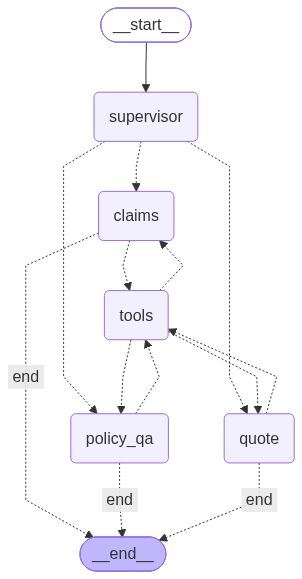

In [23]:
# ─── (Optional) Visualize the graph structure ───────────────────────
#
# LangGraph can render the graph as a Mermaid diagram. This requires
# graphviz; if it fails, the text version is shown instead.

try:
    from IPython.display import Image, display
    # draw_mermaid_png() returns PNG bytes that IPython can display
    display(Image(compiled_graph.get_graph().draw_mermaid_png()))
except Exception as e:
    # Fallback: print the Mermaid source code (you can paste it into
    # https://mermaid.live to see the diagram in your browser)
    print(f"(Couldn't draw graph: {e})")
    print("\nThe graph structure:")
    print(compiled_graph.get_graph().draw_mermaid())


### 📝 Explanation

**The graph in plain English:**

1. **Start** — every conversation begins at the START node
2. **Supervisor** — classifies the intent, sets `next_agent` in state
3. **Conditional routing** — `add_conditional_edges` lets us pick the next node dynamically based on state
4. **Specialist agents** — one of the three runs, possibly calling tools
5. **Tool executor** — runs any tools the agent requested
6. **Loop back** — control returns to the same agent so it can use the tool results
7. **End** — when an agent finalizes its response (no more tool calls), we exit

**Checkpointing** with `MemorySaver` means each conversation has a unique `thread_id` and LangGraph saves the state at every step. This lets:
- Conversations persist across turns
- Failed runs to resume from where they crashed
- Multi-turn workflows like "what about the third plan?" to work seamlessly

In production, you'd swap `MemorySaver` for `PostgresSaver` so state survives server restarts.

---
# 🧪 Section 11 — Test the Full System!

Time to put everything together and chat with our multi-agent system.

In [24]:
# ─── Section 11 — A helper function to chat with the system ─────────
#
# Wraps the graph invocation so we can call chat("Hi") instead of
# manually building input state every time.

def chat(message: str, session_id: str = "demo", damage_image: str = None) -> dict:
    """Send a message to our multi-agent system.

    Args:
        message: User's text message.
        session_id: Unique conversation ID. Same ID = same conversation
                    (multi-turn memory works automatically).
        damage_image: Optional base64-encoded damage photo.

    Returns:
        Dict with the agent's reply, intent classification, and tools used.
    """
    # ─── Config tells LangGraph WHICH conversation this is ──────────
    # thread_id is the key that the checkpointer uses to save/load state.
    # Different thread_ids = different conversations.
    config = {"configurable": {"thread_id": session_id}}

    # ─── Build the input state ──────────────────────────────────────
    # We only need to provide the NEW data — LangGraph merges this with
    # any existing state for this thread_id.
    # When a photo is attached, say so in the message itself. The model trusts
    # what the customer says more than a note in its instructions: without
    # this line it often asked the customer to upload the photo they had
    # just sent (we measured 0 of 6 runs analysing it, vs 6 of 6 with it).
    if damage_image:
        message = f"{message} (Photo of the damage attached.)"

    input_state = {
        "messages": [HumanMessage(content=message)],
        # Reset every turn: only a message that carries a photo forces claims
        "image_uploaded_this_turn": bool(damage_image),
    }

    # If a damage image was provided, include it in state.
    # The supervisor sees the flag above and routes to claims automatically.
    if damage_image:
        input_state["damage_image_b64"] = damage_image

    # ─── Run the graph ──────────────────────────────────────────────
    # .invoke() executes the entire workflow synchronously and returns
    # the final state. (.ainvoke() is the async version.)
    result = compiled_graph.invoke(input_state, config=config)

    # ─── Keep only THIS turn's messages ─────────────────────────────
    # The checkpointer returns the WHOLE conversation, so we find the latest
    # user message and look only at what came after it. Otherwise we'd show
    # replies and tool calls from earlier turns.
    all_messages = result["messages"]
    latest_user_position = max(
        position for position, past_message in enumerate(all_messages)
        if isinstance(past_message, HumanMessage)
    )
    current_turn_messages = all_messages[latest_user_position + 1:]

    # ─── Extract the final response ─────────────────────────────────
    # The last AIMessage with text in this turn is the agent's reply
    # (not just a tool-call request).
    reply = ""
    for past_message in reversed(current_turn_messages):
        if isinstance(past_message, AIMessage) and past_message.text:
            reply = past_message.text
            break

    # ─── Collect this turn's tool calls for transparency ────────────
    # Useful for debugging and showing the user what the agent did.
    tool_calls = []
    for past_message in current_turn_messages:
        if isinstance(past_message, AIMessage) and past_message.tool_calls:
            for tool_call in past_message.tool_calls:
                tool_calls.append(tool_call["name"])

    return {
        "reply": reply,
        "intent": result.get("intent"),
        "tools_used": tool_calls,
    }


def print_response(query: str, response: dict):
    """Pretty-print a chat response."""
    print("=" * 70)
    print(f"👤 USER: {query}")
    print("=" * 70)
    print(f"🤖 Intent: {response['intent']}")
    print(f"🔧 Tools used: {response['tools_used']}")
    print(f"\n📝 Reply:\n{response['reply']}")
    print()


print("✅ chat() function ready!")


✅ chat() function ready!


### 🎬 Test 1: Policy Q&A (RAG)

Let's start with the simplest path — a policy question that uses our knowledge base.

In [25]:
# ─── Test 1: Policy Q&A (uses RAG) ──────────────────────────────────
#
# This is the simplest path through the graph:
#   supervisor → policy_qa_agent → policy_kb_search → policy_qa_agent → END
#
# Watch the "tools_used" output to confirm RAG was triggered.

response = chat(
    "What is NCB and how is it transferred when I buy a new car?",
    session_id="test_qa",
)
print_response("What is NCB and how is it transferred?", response)


👤 USER: What is NCB and how is it transferred?
🤖 Intent: policy_qa
🔧 Tools used: ['policy_kb_search']

📝 Reply:
NCB (No Claim Bonus) is a discount on the **own-damage premium** for each claim-free policy year. It belongs to you, not your car, so you can transfer it when you buy a new car.

Ask your current insurer for an **NCB Retention Letter** and give it to the insurer for your new car; it is valid for **3 years**. The NCB ladder is:
- After 1 claim-free year: **20%**
- After 2 years: **25%**
- After 3 years: **35%**
- After 4 years: **45%**
- After 5 or more years: **50%**



**What just happened?**

1. Supervisor classified intent as `policy_qa` (correct!)
2. Policy Q&A agent received the question
3. It called `policy_kb_search` with a relevant query
4. ChromaDB returned the most relevant chunks (about NCB ladder + transfer rules)
5. The agent synthesized a grounded answer using those chunks

Notice how the response is **specific to our knowledge base** (mentions 3-year validity of NCB retention letter — that's exactly what `irdai_guidelines.md` says).

### 🎬 Test 2: Quote (Multi-Tool Chain)

Now the trickier test — a quote requires the agent to **chain tools** in the right order.

In [26]:
# ─── Test 2: Quote (multi-tool chain) ───────────────────────────────
#
# Trickier test — the agent must:
#   1. Call vehicle_lookup("Swift") → get specs
#   2. Use those specs to call calculate_premium(...)
#   3. Format the 3 plans into a friendly reply
#
# All without us telling it the order. The LLM figures it out from
# the tool descriptions.

response = chat(
    "I want a quote for my Maruti Swift, it's 2 years old, and I have 1 year of NCB",
    session_id="test_quote",
)
print_response("Quote for 2yr Swift with 1yr NCB", response)


👤 USER: Quote for 2yr Swift with 1yr NCB
🤖 Intent: quote
🔧 Tools used: ['vehicle_lookup', 'calculate_premium']

📝 Reply:
Here are your AutoShield quote estimates for the **2-year-old Maruti Suzuki Swift** (1,197 cc) with **1 year of NCB**:

| Plan | Estimated premium |
|---|---:|
| Third Party Only | **₹4,030** |
| Comprehensive | **₹18,757** |
| Comprehensive + Zero Depreciation | **₹20,966** |

The comprehensive plans use an estimated IDV of **₹5,20,000**. Share your **6-digit pincode** if you’d like me to check for any area-based risk loading.



**The agent's reasoning chain:**

1. Recognized: vehicle = Swift → calls `vehicle_lookup("Swift")`
2. Gets back: `{make: Maruti Suzuki, engine_cc: 1197, ex_showroom_price: 650000}`
3. Has age (2) and NCB (1) → calls `calculate_premium(650000, 2.0, 1197, 1)`
4. Gets back: 3 plan options
5. Formats them in conversational Indian English with ₹ symbols

This is **multi-step reasoning** — the agent decided the order of tool calls on its own based on what each tool needs. That's the magic of agentic AI.

### 🎬 Test 3: Claims with Photo Analysis ⭐

The showcase test — let's actually have the agent analyze our damaged car photo.

In [27]:
# ─── Test 3: Claims with photo analysis ⭐ ──────────────────────────
#
# THE showcase test. The agent must:
#   1. Verify the policy
#   2. Call analyze_damage_image (the model really looks at the photo!)
#   3. Use the cost estimate with estimate_payout
#   4. Wrap it all into a customer-friendly response
#
# We pass the base64 damage photo we downloaded earlier in Section 5.

response = chat(
    "I had an accident yesterday. My policy is POL-2026-12345. "
    "I hit a divider on the highway. Please help me file a claim.",
    session_id="test_claim",
    damage_image=image_b64,         # The base64 image from Section 5
)
print_response("File a claim with damage photo", response)


👤 USER: File a claim with damage photo
🤖 Intent: claim
🔧 Tools used: ['verify_policy', 'analyze_damage_image', 'estimate_payout']

📝 Reply:
Sorry to hear about the accident. I’ve started your claim.

- **Claim ID:** CLM-2026-90327
- **Damage:** Severe front-end damage to the hood, bumper, both headlights, and front body panels; moderate damage to the grille. Replacement is recommended.
- **Estimated repair cost:** ₹1,20,000
- **Estimated payout:** ₹81,500
- **Estimated out-of-pocket:** ₹38,500
- **Next steps:** We’ll arrange a garage referral and a surveyor visit, which is required for this claim.

For the claim record, where on the highway did the accident happen?



**This is the most impressive test in the lab.** Watch what happened:

1. Supervisor saw a photo arrived with this message (`image_uploaded_this_turn`) → immediately routed to claims (no LLM call needed for that!)
2. Claims agent verified the policy
3. Called `analyze_damage_image` — the model **actually looked at the photo** and returned structured assessment
4. Only then (one tool at a time) called `estimate_payout` with that cost estimate and the policy IDV — which also returns the claim ID
5. Wrapped everything into a customer-friendly response

This is a **full FNOL (First Notice of Loss) workflow** completed in one conversation, with real Vision AI doing the damage assessment. In a real insurance company, this kind of automation can cut claim intake time from 2 days to 5 minutes.

### 🎬 Test 4: Continuity (Same Session)

Let's see the checkpointing in action — a follow-up question in the same session should preserve context.

In [28]:
# ─── Test 4: Multi-turn continuity ──────────────────────────────────
#
# This proves checkpointing works. We use the SAME session_id for both
# turns — LangGraph automatically loads the state from Turn 1 before
# running Turn 2.

# ─── Turn 1: ask for a quote ────────────────────────────────────────
print("--- Turn 1 ---")
r1 = chat(
    "Quote for a Hyundai Creta, 3 years old, no NCB",
    session_id="continuity_test",
)
# Print just the first 300 chars to save space
print(f"Reply: {r1['reply'][:300]}...\n")

# ─── Turn 2: ask a follow-up using the SAME session_id ──────────────
# The agent should remember the quotes from Turn 1 and recommend a plan.
print("--- Turn 2 (follow-up) ---")
r2 = chat(
    "Which plan is best for me?",
    session_id="continuity_test",       # ⬅️ SAME session_id as Turn 1
)
print(f"Reply: {r2['reply'][:400]}")


--- Turn 1 ---


Reply: Here are the estimated quotes for your **3-year-old Hyundai Creta** with **0 NCB**:

- **Third Party Only:** ₹4,030
- **Comprehensive:** ₹32,527
- **Comprehensive + Zero Depreciation:** ₹36,801

These totals include GST. A pincode can help check whether any local risk loading applies....

--- Turn 2 (follow-up) ---


Reply: **Comprehensive + Zero Depreciation** may suit you best if you want protection for damage to your own Creta as well as third-party liability. Zero Depreciation avoids depreciation deductions on replaced parts and is generally best for cars under 5 years old; it costs about **₹4,274 more** than the comprehensive quote.

Choose **Comprehensive** if you want own-damage cover but prefer the lower prem


**What you should see:**

- Turn 1: Agent presents 3 plans for a 3-year Creta with no NCB
- Turn 2: Agent **knows the context** — it can recommend a plan because it remembers the previous quote

This works because we passed `session_id="continuity_test"` both times. LangGraph's checkpointer loaded the previous state (including messages and stored quote results) before running Turn 2.

**Without checkpointing**, the agent would say "I don't know which plans you're talking about — please ask for a quote first." That breaks the user experience.

---
# 🚀 Section 13 — What You Built & What's Next

## 🎉 Congratulations!

You've built a complete multi-agent AI system from scratch. Let's recap what you have:

| Layer | What you built |
|---|---|
| **Domain logic** | IRDAI-compliant premium calculator (IDV, NCB, OD, TP, GST) |
| **Data** | Vehicle catalog + 3-document knowledge base in ChromaDB |
| **Tools** | 7 tools across 3 categories (quote, claims, RAG) |
| **Vision AI** | Damage analysis from a photo (`gpt-6-luna`) |
| **Multi-agent** | Supervisor + 3 specialists with LangGraph |
| **State** | Stateful conversations via checkpointing |
| **UI** | Optional chat interface |

That's **~600 lines of Python** that implement a system you could actually demo to an insurance company.

## 📈 Skills you practiced

✅ Designing tools with Pydantic schemas

✅ Building LangGraph workflows with supervisor pattern

✅ Using multimodal AI (photo analysis with `gpt-6-luna`)

✅ Implementing RAG with ChromaDB + embeddings

✅ Conditional routing in LangGraph

✅ Stateful conversations with checkpointing

✅ Working with a reasoning model (no `temperature`; `reasoning_effort` controls speed and cost)

## 🌱 Where to take this next

### **Deploy it on cloud**
- The repo at [github.com/prashant9501/car-insurance-agent-deployment](https://github.com/prashant9501/car-insurance-agent-deployment) has a FastAPI backend + HTML frontend + Dockerfile
- Use the `setup_ec2.sh` script to deploy to an AWS EC2 instance in 10 minutes
- Add HTTPS with Let's Encrypt for a public demo URL

## 💼 How to talk about this in interviews

**Don't say**: "I built a chatbot"

**Do say**: "I built a multi-agent insurance system using LangGraph's supervisor pattern. The supervisor routes intents to one of 3 specialist agents — Quote, Claims (with AI photo damage analysis), and Policy Q&A (with RAG over IRDAI documents). It uses Indian motor insurance math (IDV, NCB ladder, OD/TP split, GST) and persists state via LangGraph checkpointing. Deployed via Docker + NGINX on AWS EC2."

That second framing is 10x more impressive because it shows:
- Awareness of **design patterns** (supervisor)
- **Multimodal AI** experience
- **RAG** experience
- **Domain modeling** depth
- **Production deployment** experience

## 📚 Recommended reading

- [LangGraph documentation](https://langchain-ai.github.io/langgraph/) — especially "Multi-agent systems"
- [The original supervisor pattern paper](https://blog.langchain.dev/langgraph-multi-agent-workflows/) from LangChain
- [IRDAI motor insurance regulations](https://www.irdai.gov.in) — if you want to go deeper on Indian insurance

## 🙏 Thank you for building this lab!

If you found this useful:
- ⭐ Star the repo: [github.com/prashant9501/car-insurance-agent-deployment](https://github.com/prashant9501/car-insurance-agent-deployment)
- 🎥 Record a demo video and share on LinkedIn — tag K21 Academy

Happy building! 🚗💨